In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/previous_application_filtered.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/installments_payments_filtered.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/application_train_filtered.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/bureau_filtered.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/POS_CASH_balance_filtered.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/bureau_balance_filtered.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/credit_card_balance_filtered.csv


# Notebook Purpose

Với EDA - Part 2, tập trung vào việc xem xét các phân phối dữ liệu của từng cột trong từng tập Dataset, sử dụng KDE or Barplot, Countplot

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import matplotlib.ticker as mticker
import math
import itertools
from typing import Literal
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import seaborn.objects as so

In [2]:
application_train_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/application_train_filtered.csv')
bureau_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/bureau_filtered.csv')
bureau_balance_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/bureau_balance_filtered.csv')
credit_card_balance_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/credit_card_balance_filtered.csv')
installments_payments_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/installments_payments_filtered.csv')
previous_application_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/previous_application_filtered.csv')
POS_CASH_balance_filtered = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-filtered/POS_CASH_balance_filtered.csv')

In [3]:
application_train_filtered.drop(columns=['Unnamed: 0'], inplace=True)
bureau_filtered.drop(columns=['Unnamed: 0'], inplace=True)
bureau_balance_filtered.drop(columns=['Unnamed: 0'], inplace=True)
credit_card_balance_filtered.drop(columns=['Unnamed: 0'], inplace=True)
installments_payments_filtered.drop(columns=['Unnamed: 0'], inplace=True)
previous_application_filtered.drop(columns=['Unnamed: 0'], inplace=True)
POS_CASH_balance_filtered.drop(columns=['Unnamed: 0'], inplace=True)

# Kiểm tra phân phối

In [4]:
class KDEPlot:
    """
    Create single and multiple box plots
    """
    def __init__(self, df: pd.DataFrame):
        self.df = df

    @staticmethod
    def readable_numbers(x: float) -> str:
        """
        takes a large number and formats it into K,M to make it more readable

        Args
            x: float value to format

        Returns
            str: formatted string
        """
        if x >= 1e6:
            s = '{:1.1f}M'.format(x*1e-6)
        elif x >= 1e3:
            s = '{:1.1f}K'.format(x*1e-3)
        else:
            s = x
        return s

    def set_locator(self, axes: Axes):
        """
        Format x, y ticklabels into more readable form

        Args
            axes: matplotlib axes to format x, y ticklabels
        """
        def is_number(x):
            x = x.replace('−', '-')
            try:
                float(x)
                return True
            except ValueError:
                return False
    
        x_ticklabels = [tick.get_text() for tick in axes.get_xticklabels()]
        y_ticklabels = [tick.get_text() for tick in axes.get_yticklabels()]

        formatter = FuncFormatter(lambda val, pos: self.readable_numbers(val))

        if is_number(x_ticklabels[1]) == True:
            axes.xaxis.set_major_formatter(formatter)
        if is_number(y_ticklabels[1]) == True:
            axes.yaxis.set_major_formatter(formatter)

    def single_plot(
        self,
        x_axis: str,
        y_axis: str | None,
        hue: str | None,
        kwarg: dict | None = None,
        readable_label: bool = False,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable Box Plot.
    
        Args:
            x_axis: column needed
            y_axis: column needed
            hue: column needed
            dimension: '1d' for single variable, '2d' for grouped boxplot
            readable_label: whether to format x/y tick labels for readability
            ax: matplotlib axes to draw plot
            kwarg: additional seaborn arguments
        """
        
        if ax is None:
            ax = plt.gca()
        if kwarg is None:
            kwarg = {}
            
        # --- Styling palette and defaults ---
        sns.set_style("whitegrid")  # clean background
        palette = sns.color_palette('pastel')
        # or: "rocket", "magma", "coolwarm", "crest", "flare", "viridis"

        if hue is None:
            palette = None
        
        kde = sns.kdeplot(
            data=self.df,
            x=x_axis,
            y=y_axis,
            hue=hue,
            ax=ax,
            palette=palette,
            **kwarg
        )

        
        ax.set_xlabel(x_axis, fontsize=13, labelpad=8)
        ax.set_ylabel(y_axis, fontsize=13, labelpad=8)

        # if hue is not None:
        #     ax.legend(
        #         title=hue if hue else "",
        #         frameon=True,
        #         fancybox=True,
        #         framealpha=0.8,
        #         fontsize=11,
        #         title_fontsize=12,
        #         loc="best",
        #     )
    
        # --- Titles & Ticks ---
        ax.set_title(
            f"KDE Plot",
            fontdict={"fontsize": 12, "fontweight": "regular", 
                      # "fontname": "Times New Roman"
                     },
            pad=15
        )
        ax.tick_params(axis="x", labelrotation=0, labelsize=11)
        ax.tick_params(axis="y", labelrotation=0, labelsize=11)
    
        # --- Optional: readable tick labels ---
        if readable_label:
            self.set_locator(ax)
    
        # --- Clean up look ---
        sns.despine(ax=ax, top=True, right=True)
        ax.grid(axis="y", linestyle="--", alpha=0.6)
    
        return kde
    
    def multiple_plots(self, y_axis_list: list[str|None], x_axis_list: list[str], kwarg: dict|None,
                       hue_list: list[str|None], plots_each_row: int, 
                       readable_label: bool = False) -> (Figure, np.array([Axes])):
        """
        Draw multiple box plots
        
        Args
            Same as single_plot
            y_axis_list: list of columns for y axis
            plots_each_row: number of plots for each row in matplotlib figure
        """
        combination = list(zip(x_axis_list, y_axis_list, hue_list))
        
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(16, 8),
                                ) # sharey=True: same y_axis scale
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            x, y, hue = com
            ax = axes[coor]
            self.single_plot(
                x_axis=x,
                y_axis=y,
                hue=hue,
                readable_label=readable_label,
                kwarg=kwarg,
                ax=ax
            )
    
        # hide any unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])
    
        fig.tight_layout()

        return fig, axes

In [20]:
class CountPlot:
    def __init__(self, df:pd.DataFrame):
        self.df = df

    @staticmethod
    def readable_numbers(x: float) -> str:
        """
        takes a large number and formats it into K,M to make it more readable

        Args
            x: float value to format

        Returns
            str: formatted string
        """
        if x >= 1e6:
            s = '{:1.2f}M'.format(x*1e-6)
        else:
            s = '{:1.2f}K'.format(x*1e-3)
        return s
    
    def set_locator(self, axes: Axes):
        """
        Format x, y ticklabels into more readable form

        Args
            axes: matplotlib axes to format x, y ticklabels
        """
        def is_number(x):
            x = x.replace('−', '-')
            try:
                float(x)
                return True
            except ValueError:
                return False
    
        x_ticklabels = [tick.get_text() for tick in axes.get_xticklabels()]
        y_ticklabels = [tick.get_text() for tick in axes.get_yticklabels()]
    
        formatter = FuncFormatter(lambda val, pos: self.readable_numbers(val))

        if is_number(x_ticklabels[0]) == True:
            axes.xaxis.set_major_formatter(formatter)
        if is_number(y_ticklabels[0]) == True:
            axes.yaxis.set_major_formatter(formatter)

    def single_plot(
        self,
        x_axis: str,
        hue: str | None,
        kwarg: dict|None = None,
        readable_label: bool = False,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable bar plot.
    
        Args:
            x_axis: column for x-axis
            y_axis: column for y-axis
            hue: column to group bars (optional)
            readable_label: whether to display readable number labels
            ax: matplotlib axes to draw plot
            kwarg: other keyword arguments (e.g., from seaborn barplot)
        """
    
        # --- Setup Axes ---
        if ax is None:
            ax = plt.gca()
        if kwarg is None:
            kwarg = {}

        if hue is None:
            palette = None
        else:
            # --- 🌟 Modern aesthetic theme ---
            palette = sns.color_palette("Spectral", n_colors=self.df[hue].nunique()) if hue else "viridis"
            # or: "rocket", "magma", "coolwarm", "crest", "flare", "viridis"
        
        # --- Draw the barplot ---
        count = sns.countplot(
            data=self.df,
            x=x_axis,
            hue=hue,
            ax=ax,
            palette=palette,
            edgecolor="black",
            linewidth=1.2,
            **kwarg
        )
    
        # --- 🧠 Title & Labels ---
        ax.set_title(
            f'CountPlot',
            fontdict={
                'fontsize': 12,
                'fontweight': 'regular',
                # 'fontname': 'Times New Roman'
            },
            pad=5
        )
        ax.set_xlabel(x_axis, fontsize=12, labelpad=8)
        ax.set_ylabel('Count', fontsize=12, labelpad=8)
    
        # --- ✨ Ticks & Grid ---
        ax.tick_params(axis='x', labelsize=10, rotation=0)
        ax.tick_params(axis='y', labelsize=10)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('gray')
        ax.spines['bottom'].set_color('gray')
    
        # --- 🎨 Legend ---
        if hue is not None:
            ax.legend(
                title=hue,
                title_fontsize=11,
                fontsize=10,
                loc='best',
                frameon=False
            )
    
        # --- 💬 Bar labels ---
        if readable_label:
            for container in count.containers:
                labels = [self.readable_numbers(p.get_height()) for p in container]
                count.bar_label(
                    container,
                    labels=labels,
                    label_type='edge',
                    fontsize=9,
                    fontname='Times New Roman',
                    color='black',
                    padding=2
                )
            self.set_locator(count)
    
        # # --- 🌤️ Tighten layout ---
        # plt.tight_layout()
    
        return count

    def multiple_plots(self, x_axis_list: list[str], hue_list: list[str|None], plots_each_row: int,
                       kwarg: dict|None = None, readable_label: bool = False) -> (Figure, np.array([Axes])):
        """
        Draw multiple plots

        Args
            Same as single_plot
            x_axis_list: list of columns for x axis
            plots_each_row: number of plots for each row in matplotlib figure
            kwarg: other keyword arguments if needed.
        """
        
        combination = list(zip(x_axis_list, hue_list))
        
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(20, 16),
                                sharey=False) # same y_axis scale
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            x, hue = com
            ax = axes[coor]
            self.single_plot(
                x_axis=x,
                hue=hue,
                readable_label=readable_label,
                kwarg=kwarg,
                ax=ax,
            )
    
        # hide any unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])

        fig.tight_layout(pad=2.5)

        return fig, axes

In [6]:
class PieChart:
    def __init__(self, df:pd.DataFrame):
        self.df = df

    def single_plot(
        self,
        column: str, 
        kwarg: dict=None,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable bar plot.
    
        Args:
            x_axis: column for x-axis
            y_axis: column for y-axis
            ax: matplotlib axes to draw plot
            kwarg: other keyword arguments (e.g., from plot)
        """
    
        # --- Setup Axes ---
        if ax is None:
            ax = plt.gca()
    
        # --- 🌟 Modern aesthetic theme ---
        palette = sns.color_palette('pastel')
        # or: "rocket", "magma", "coolwarm", "crest", "flare", "viridis"
        
        # --- Draw the barplot ---
        series = self.df[column].value_counts(normalize=True)
        data=series.values
        labels=series.index

        if kwarg is None:
            kwarg = {}

        wedges, texts, autotexts = ax.pie(
            x=data,
            labels=labels,
            colors=palette,
            startangle=90,
            autopct='%1.1f%%',
            wedgeprops=dict(edgecolor='black'), # width=0.5
            **kwarg
        )
    
        # --- 🧠 Title & Labels ---
        ax.set_title(
            f'Pie Chart for {column}',
            fontdict={
                'fontsize': 12,
                # 'fontweight': 'bold',
                # 'fontname': 'Times New Roman'
            },
            pad=4
        )
    
        # ax.legend(labels, title="Classes", loc="best", 
        #           bbox_to_anchor=(1, 0, 0.5, 1), frameon=False)

        # # --- 🌤️ Tighten layout ---
        # plt.tight_layout()
    
        return ax

    def multiple_plots(self, column_list: list[str], plots_each_row: int,
                   kwarg: dict = None) -> tuple[Figure, np.ndarray]:
        combination = column_list
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        # Scale figure size with number of rows & columns
        fig_width  = 5.5 * plots_each_row          # ~5.5 inch per column
        fig_height = 4.5 * number_rows             # ~4.5 inch per row
        fig, axes = plt.subplots(
            nrows=number_rows,
            ncols=plots_each_row,
            figsize=(fig_width, fig_height),
            sharey=False
        )
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            column = com
            ax = axes[coor]
            self.single_plot(column=column, kwarg=kwarg, ax=ax)
    
        # Hide unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])
    
        # Important: give the pies room
        fig.tight_layout(pad=2.5)          # or try pad=1.5 ~ 3.0
        # Alternative if tight_layout is not enough:
        # fig.subplots_adjust(hspace=0.45, wspace=0.25)
    
        return fig, axes

## Cho application_train

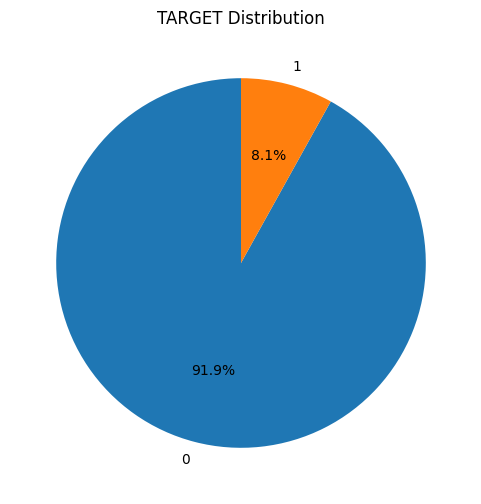

In [8]:
# phân phối của target
application_train_filtered['TARGET'].value_counts(normalize=True).plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    figsize=(6, 6),
    title='TARGET Distribution'
)
plt.ylabel('')  # bỏ nhãn trục y
plt.show()

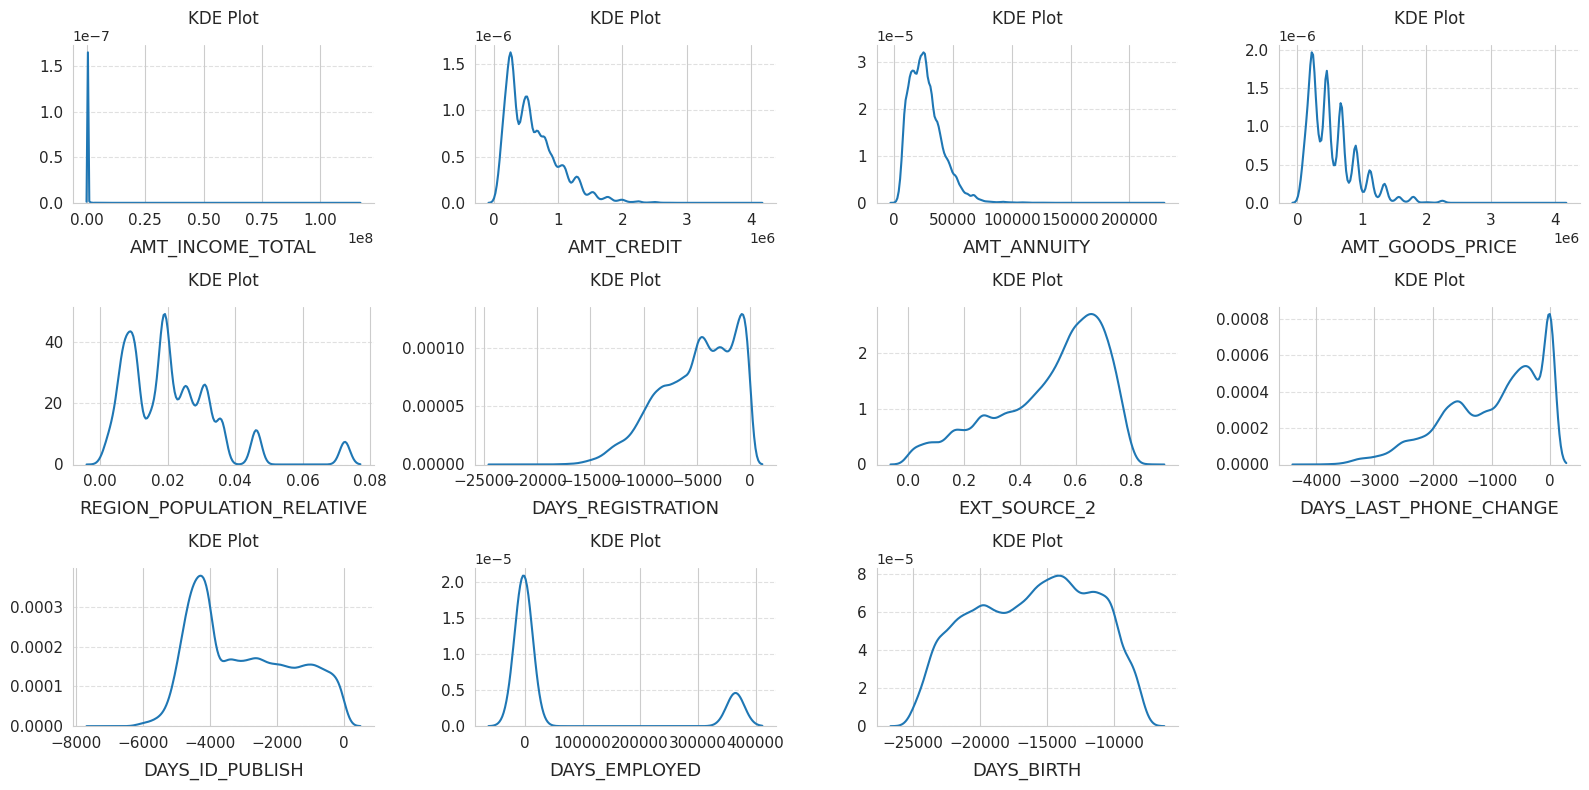

In [41]:
application_train_float = application_train_filtered.select_dtypes(include=['float64'])
application_train_float = application_train_float.drop(columns=['DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'CNT_FAM_MEMBERS'])
application_train_float = pd.concat([application_train_float, application_train_filtered[['DAYS_ID_PUBLISH', 'DAYS_EMPLOYED', 'DAYS_BIRTH']]], axis=1)

all_columns = list(application_train_float.columns)

kdeplotter = KDEPlot(application_train_float)
kde_arg = {
    'x_axis_list': all_columns,
    'y_axis_list': [None for _ in range(len(all_columns))],
    'hue_list': [None for _ in range(len(all_columns))],
    'readable_label': False,
    'plots_each_row': 4,
    'kwarg': dict(fill=False, alpha=1)
}

fig, axes = kdeplotter.multiple_plots(**kde_arg)

In [11]:
application_train_int = application_train_filtered.select_dtypes(include=['int64'])
application_train_int = pd.concat([application_train_int, application_train_filtered[['DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'CNT_FAM_MEMBERS']]], axis=1)
application_train_int = application_train_int.drop(columns=['TARGET', 'SK_ID_CURR'])
application_train_int

binary_cols = [
    col for col in application_train_int.columns 
    if set(application_train_int[col].dropna().unique()).issubset({0, 1})
]

all_cols = application_train_int.columns
nonbinary_cols = list(set(all_cols) - set(binary_cols))

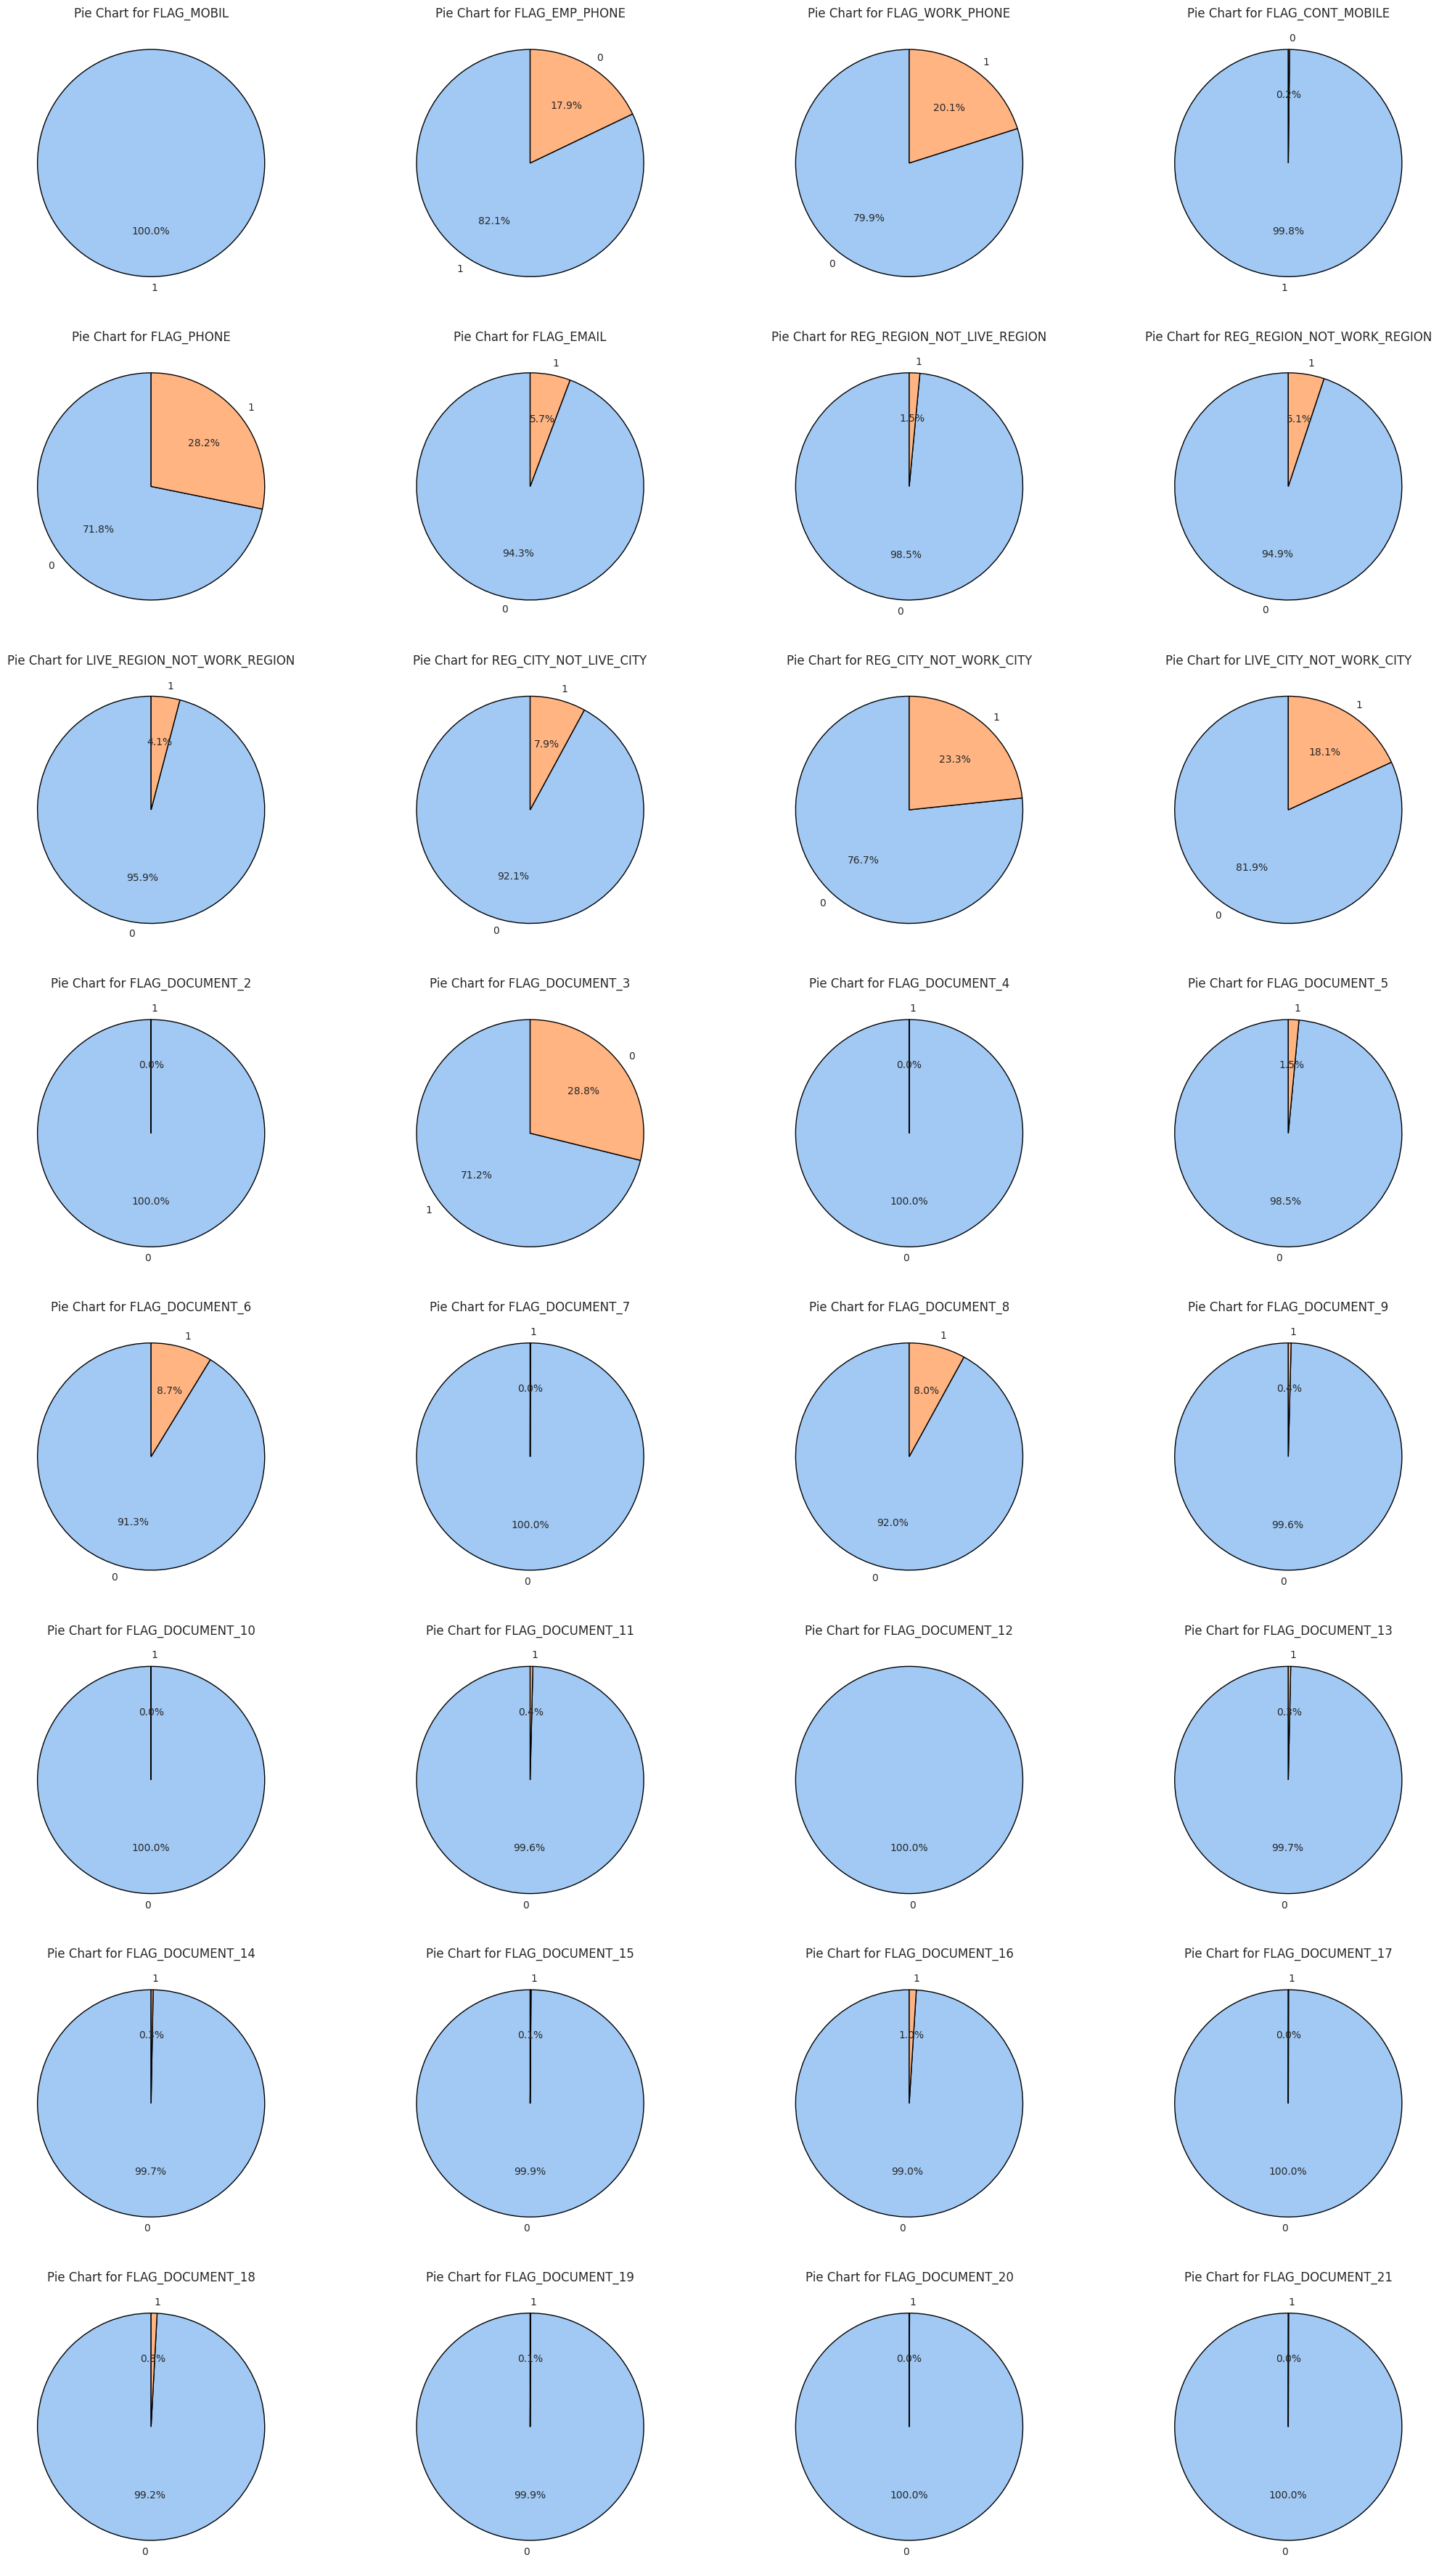

In [39]:
application_train_int_binary = application_train_int[binary_cols]

pieplotter = PieChart(application_train_int_binary)
all_cols = list(application_train_int_binary.columns)

pie_arg = {
    'column_list': all_cols,
    'plots_each_row': 4,
    'kwarg': None
}

fig, pies = pieplotter.multiple_plots(**pie_arg)

có rất nhiều cột có giá trị rất lệch, nhiều cột có nhị phân có giá trị = 1 chiếm chưa đến 0.1%, các cột này sẽ bị loại bỏ vì sẽ không đem lại nhiều thông tin cho mô hình và có thể khiến model bias

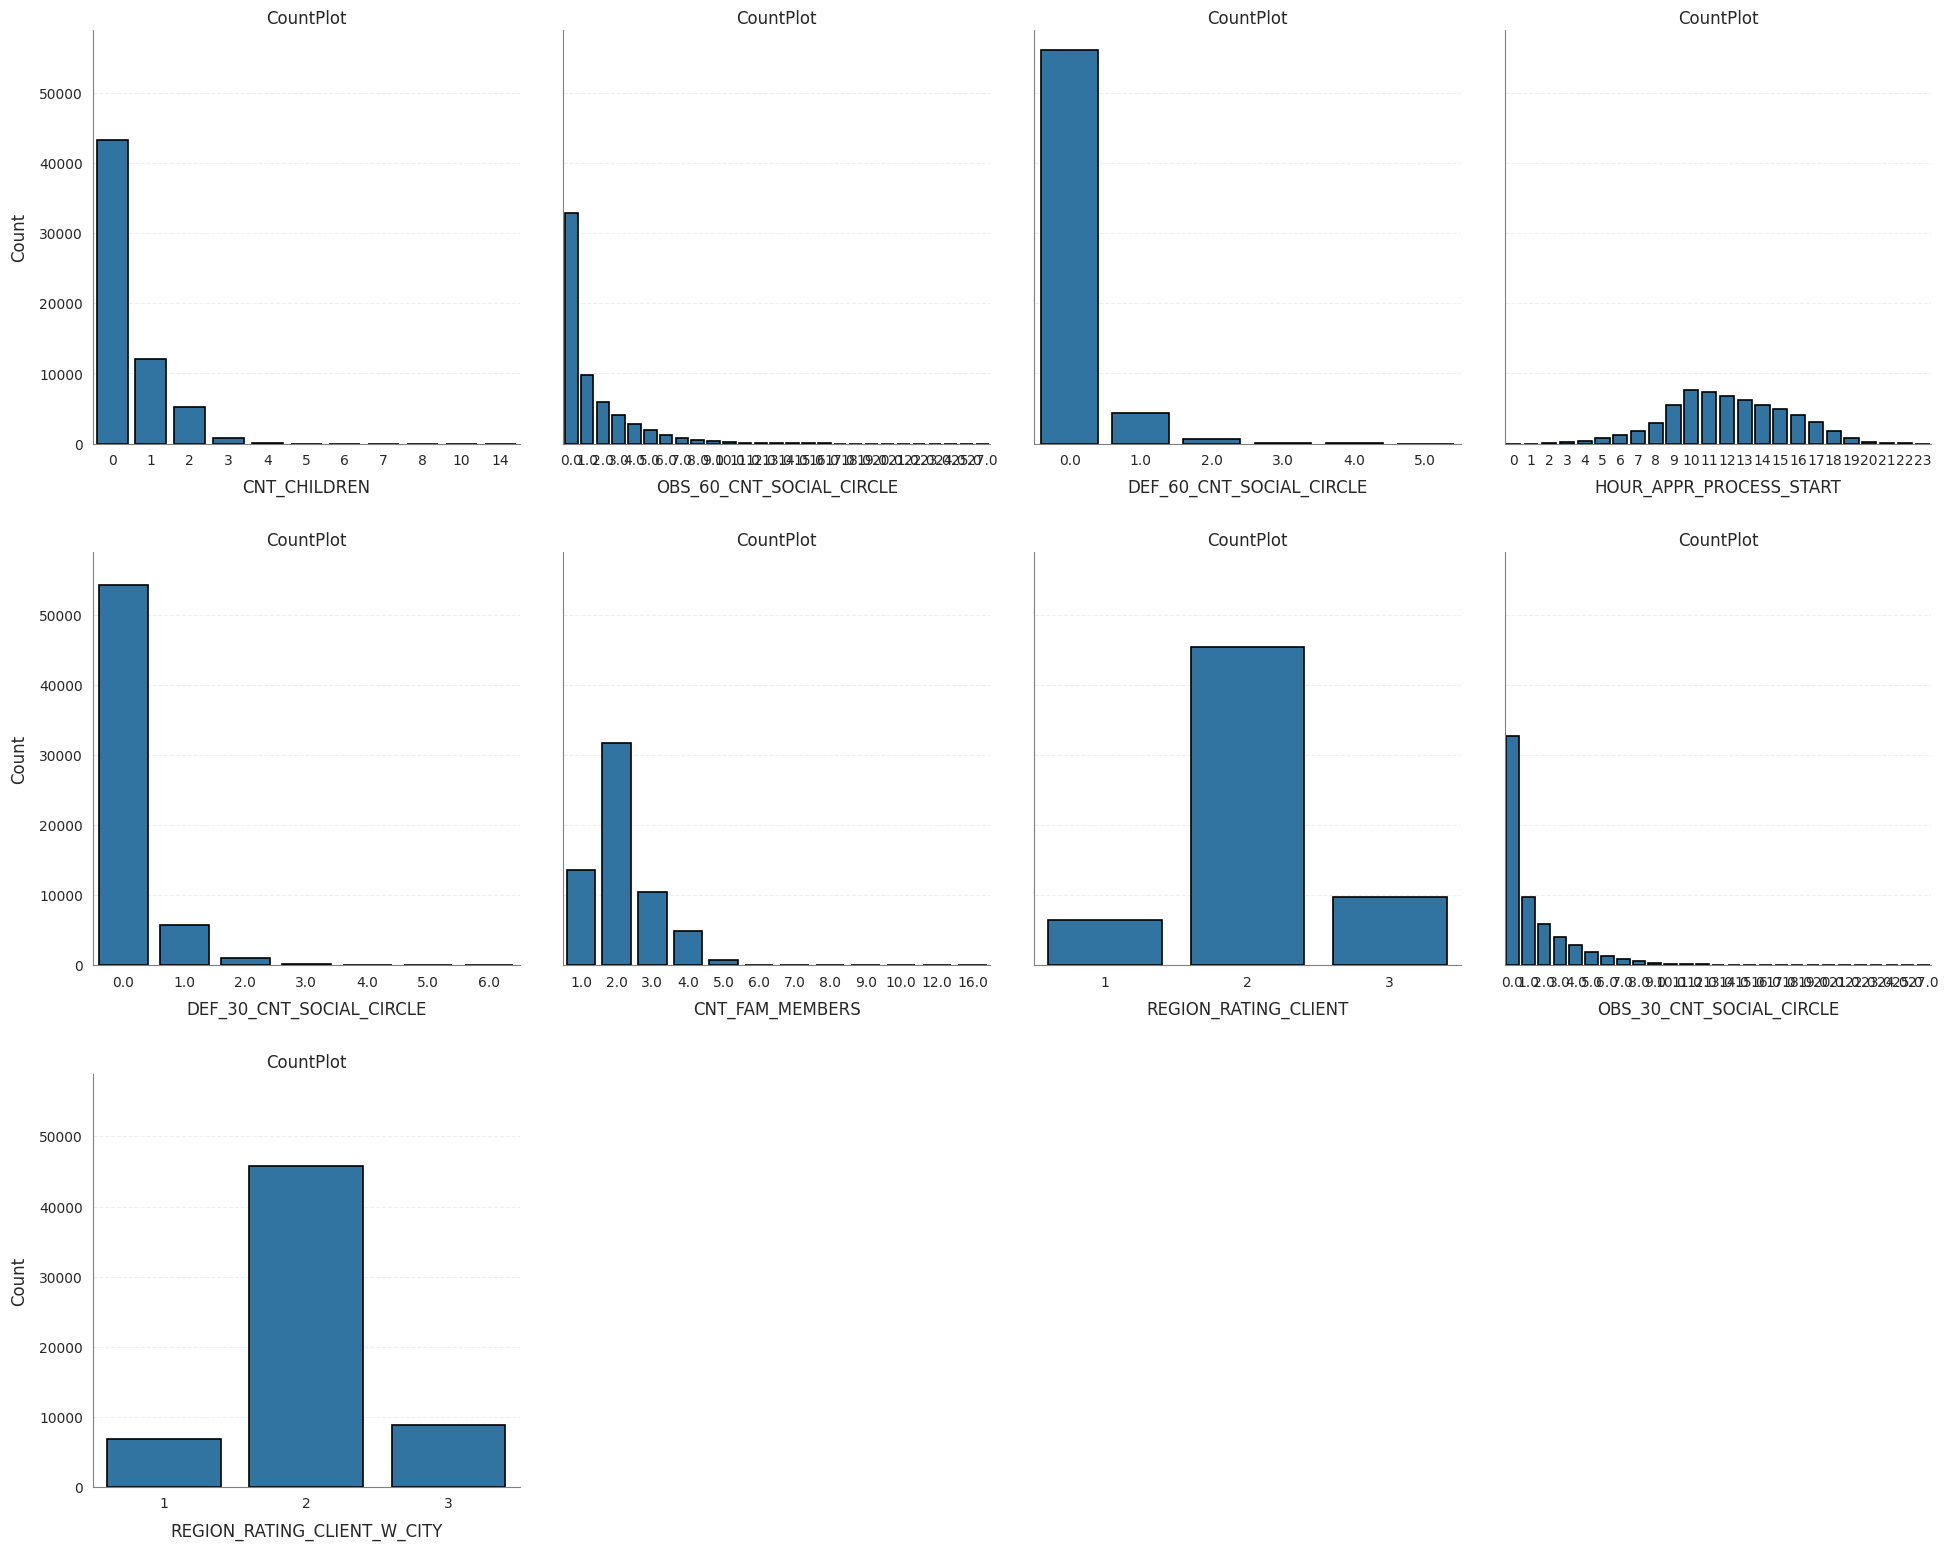

In [47]:
# một số cột trong application_train_int_nonbinary có rất nhiều giá trị nguyên khác nhau, 
# không lý tưởng để dùng countplot -> vẫn dùng KDE cho các cột này

application_train_int_nonbinary = application_train_int[nonbinary_cols].copy()
application_train_int_nonbinary.drop(columns=['DAYS_ID_PUBLISH', 'DAYS_EMPLOYED', 'DAYS_BIRTH'], inplace=True)
all_columns = list(application_train_int_nonbinary.columns)

countplotter = CountPlot(application_train_int_nonbinary)
x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=4, readable_label=False)

Có nhiều cột có phân phối lệch và có outlier nên sẽ cần xử lý bằng cách winsorisation hoặc dùng log transform để giảm tác động của outliers và tạo ra phân phối mới ít lệch hơn (đạt được bằng cách dùng log transform)

Phân phối giữa REGION_RATING_CLIENT_W_CITY và REGION_RATING_CLIENT có phân phối giống nhau -> 2 cột này có sự trùng lặp thông tin cao -> loại bỏ 1 cột

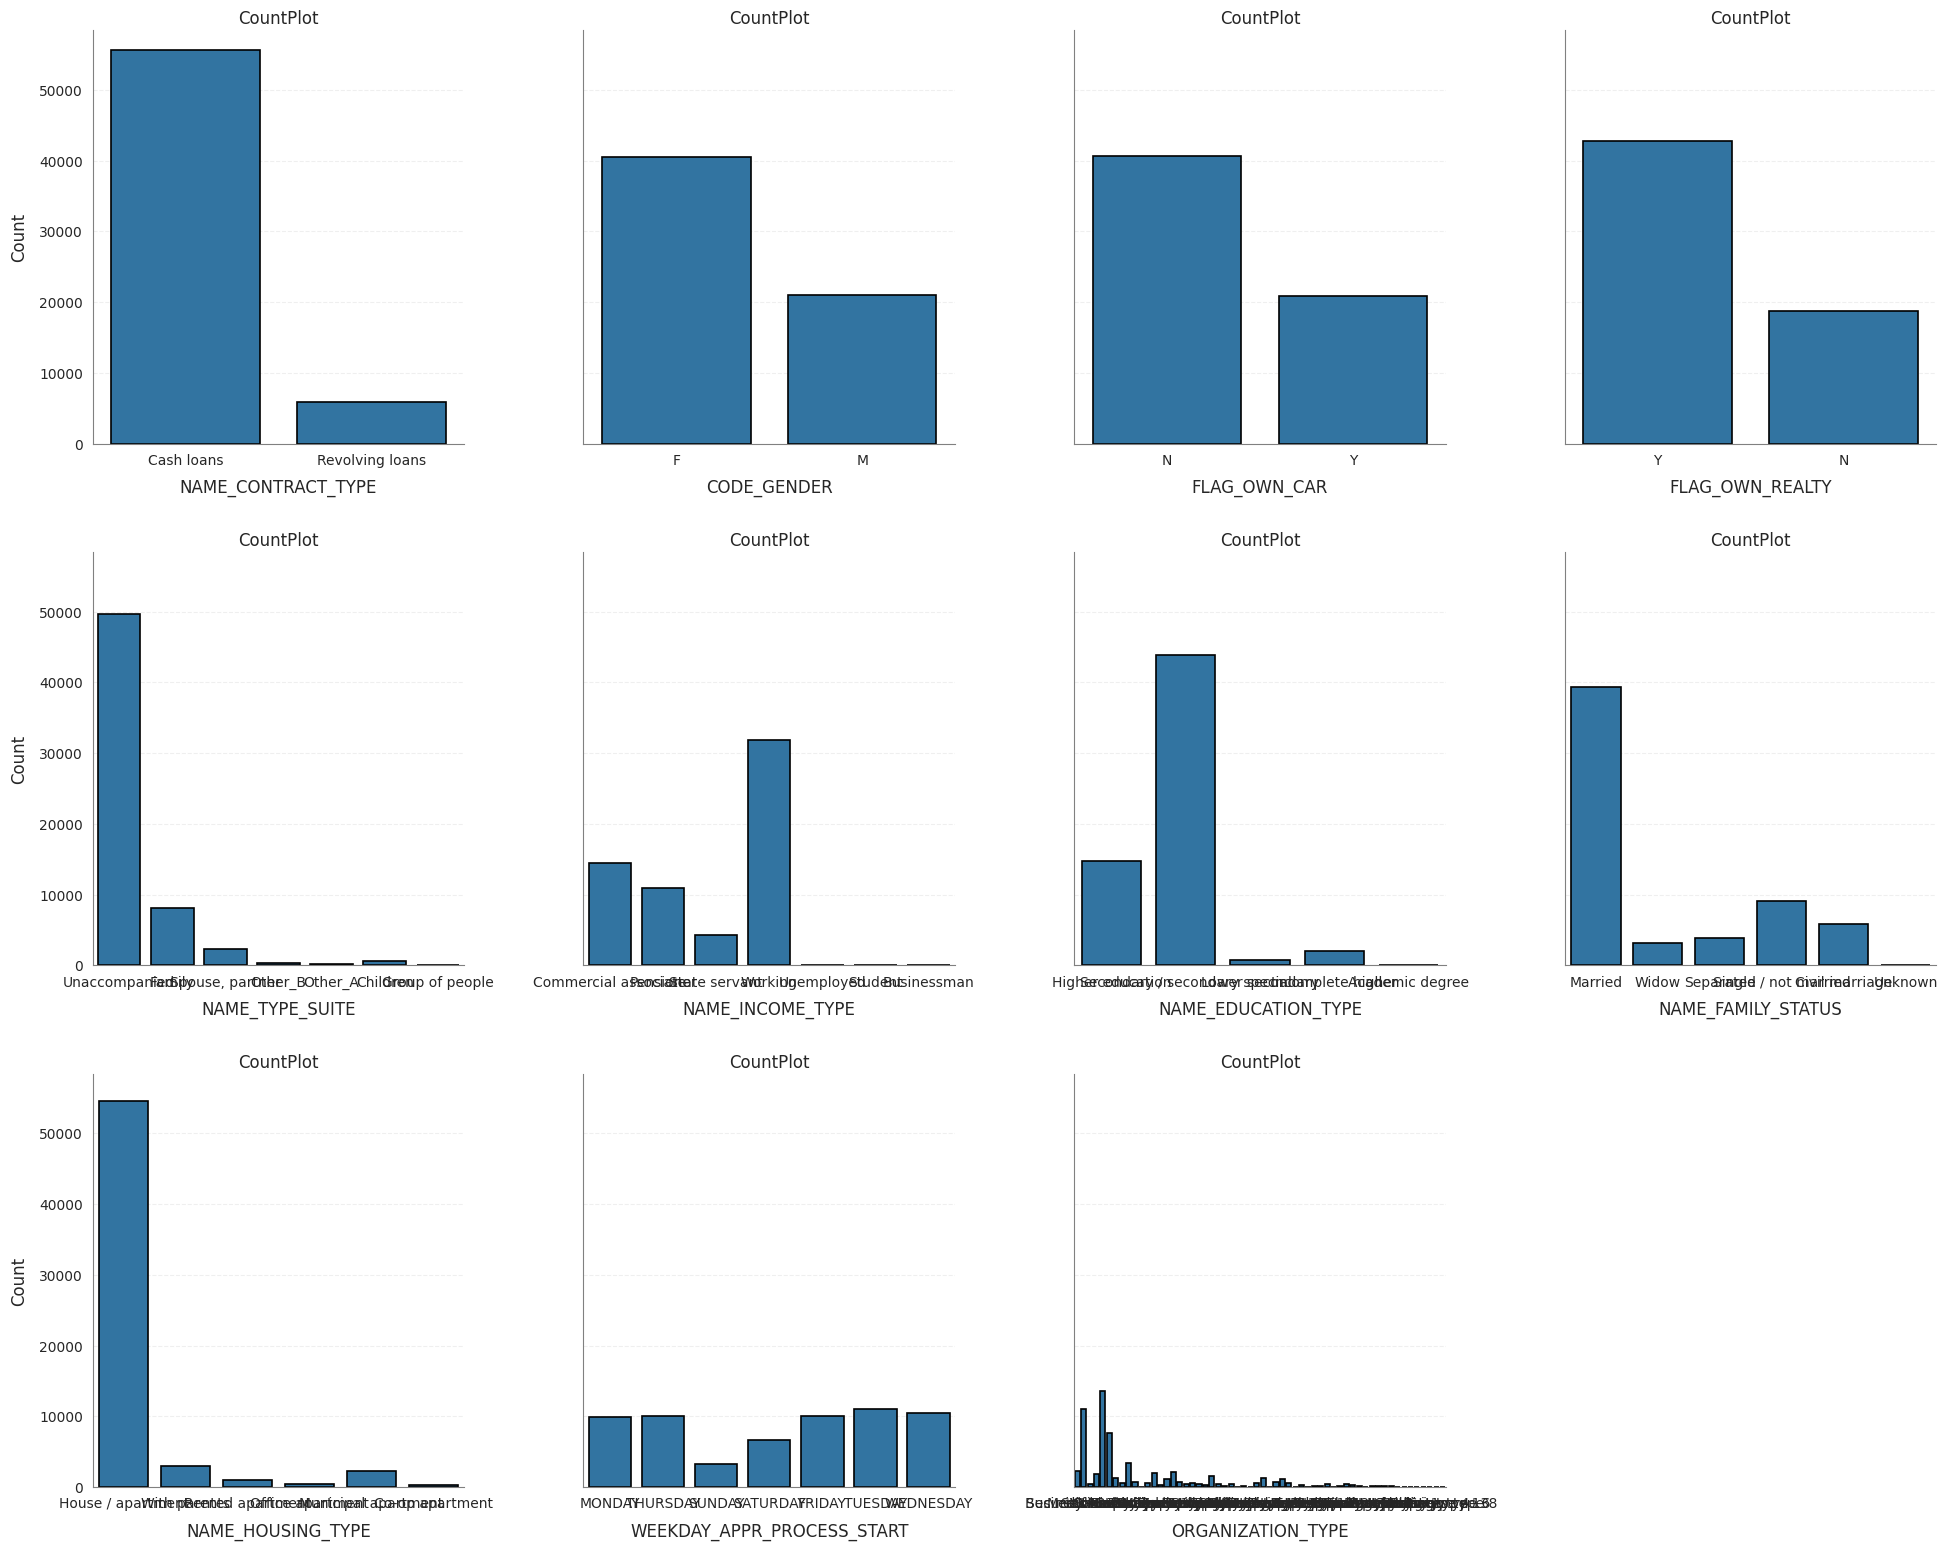

In [54]:
application_train_object = application_train_filtered.select_dtypes(include=['object'])
all_columns = list(application_train_object.columns)

countplotter = CountPlot(application_train_object)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=4, readable_label=False)

Một số cột có sự lệch dữ liệu rất lớn nên cần có cách xử lý

## Cho bureau

In [71]:
bureau_object = bureau_filtered.select_dtypes(include=['object'])
bureau_int = bureau_filtered.select_dtypes(include=['int64'])
bureau_float = bureau_filtered.select_dtypes(include=['float64'])

bureau_int.drop(columns=['SK_ID_CURR', 'SK_ID_BUREAU', 'DAYS_CREDIT', 'DAYS_CREDIT_UPDATE'], inplace=True)
bureau_float = pd.concat([bureau_float, bureau_filtered[['DAYS_CREDIT', 'DAYS_CREDIT_UPDATE']]], axis=1)

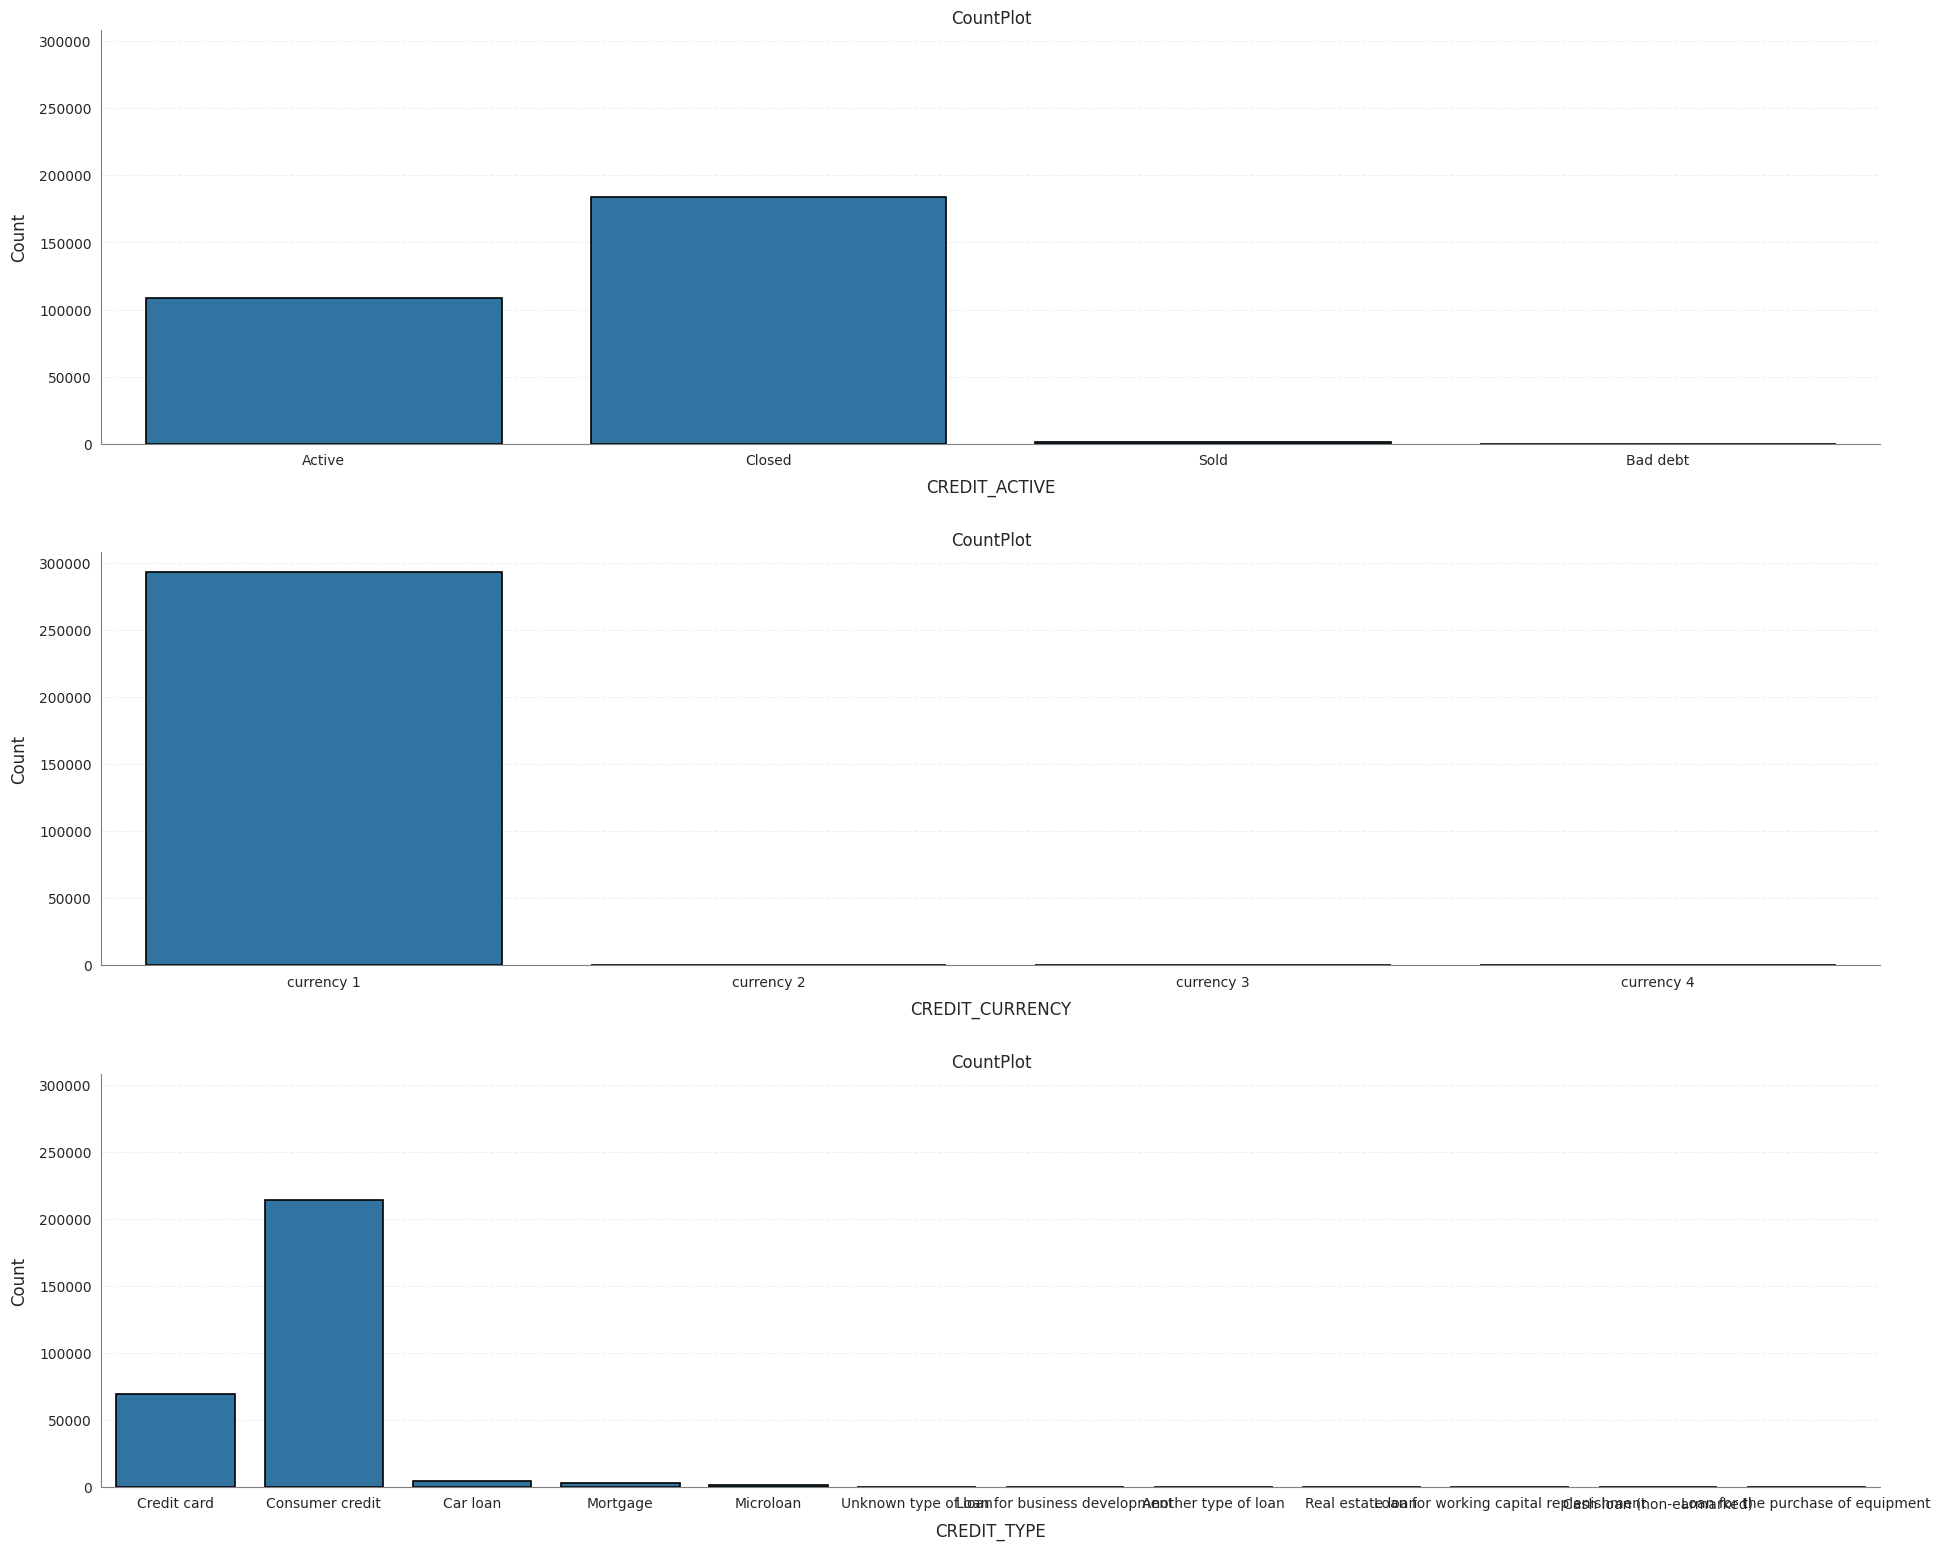

In [59]:
# phân phối của dtype object
all_columns = list(bureau_object.columns)

countplotter = CountPlot(bureau_object)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

Credit currency có thể bỏ đi
các cột khác có thể xử lý bằng cách gom nhóm sử dụng Frequency Grouping

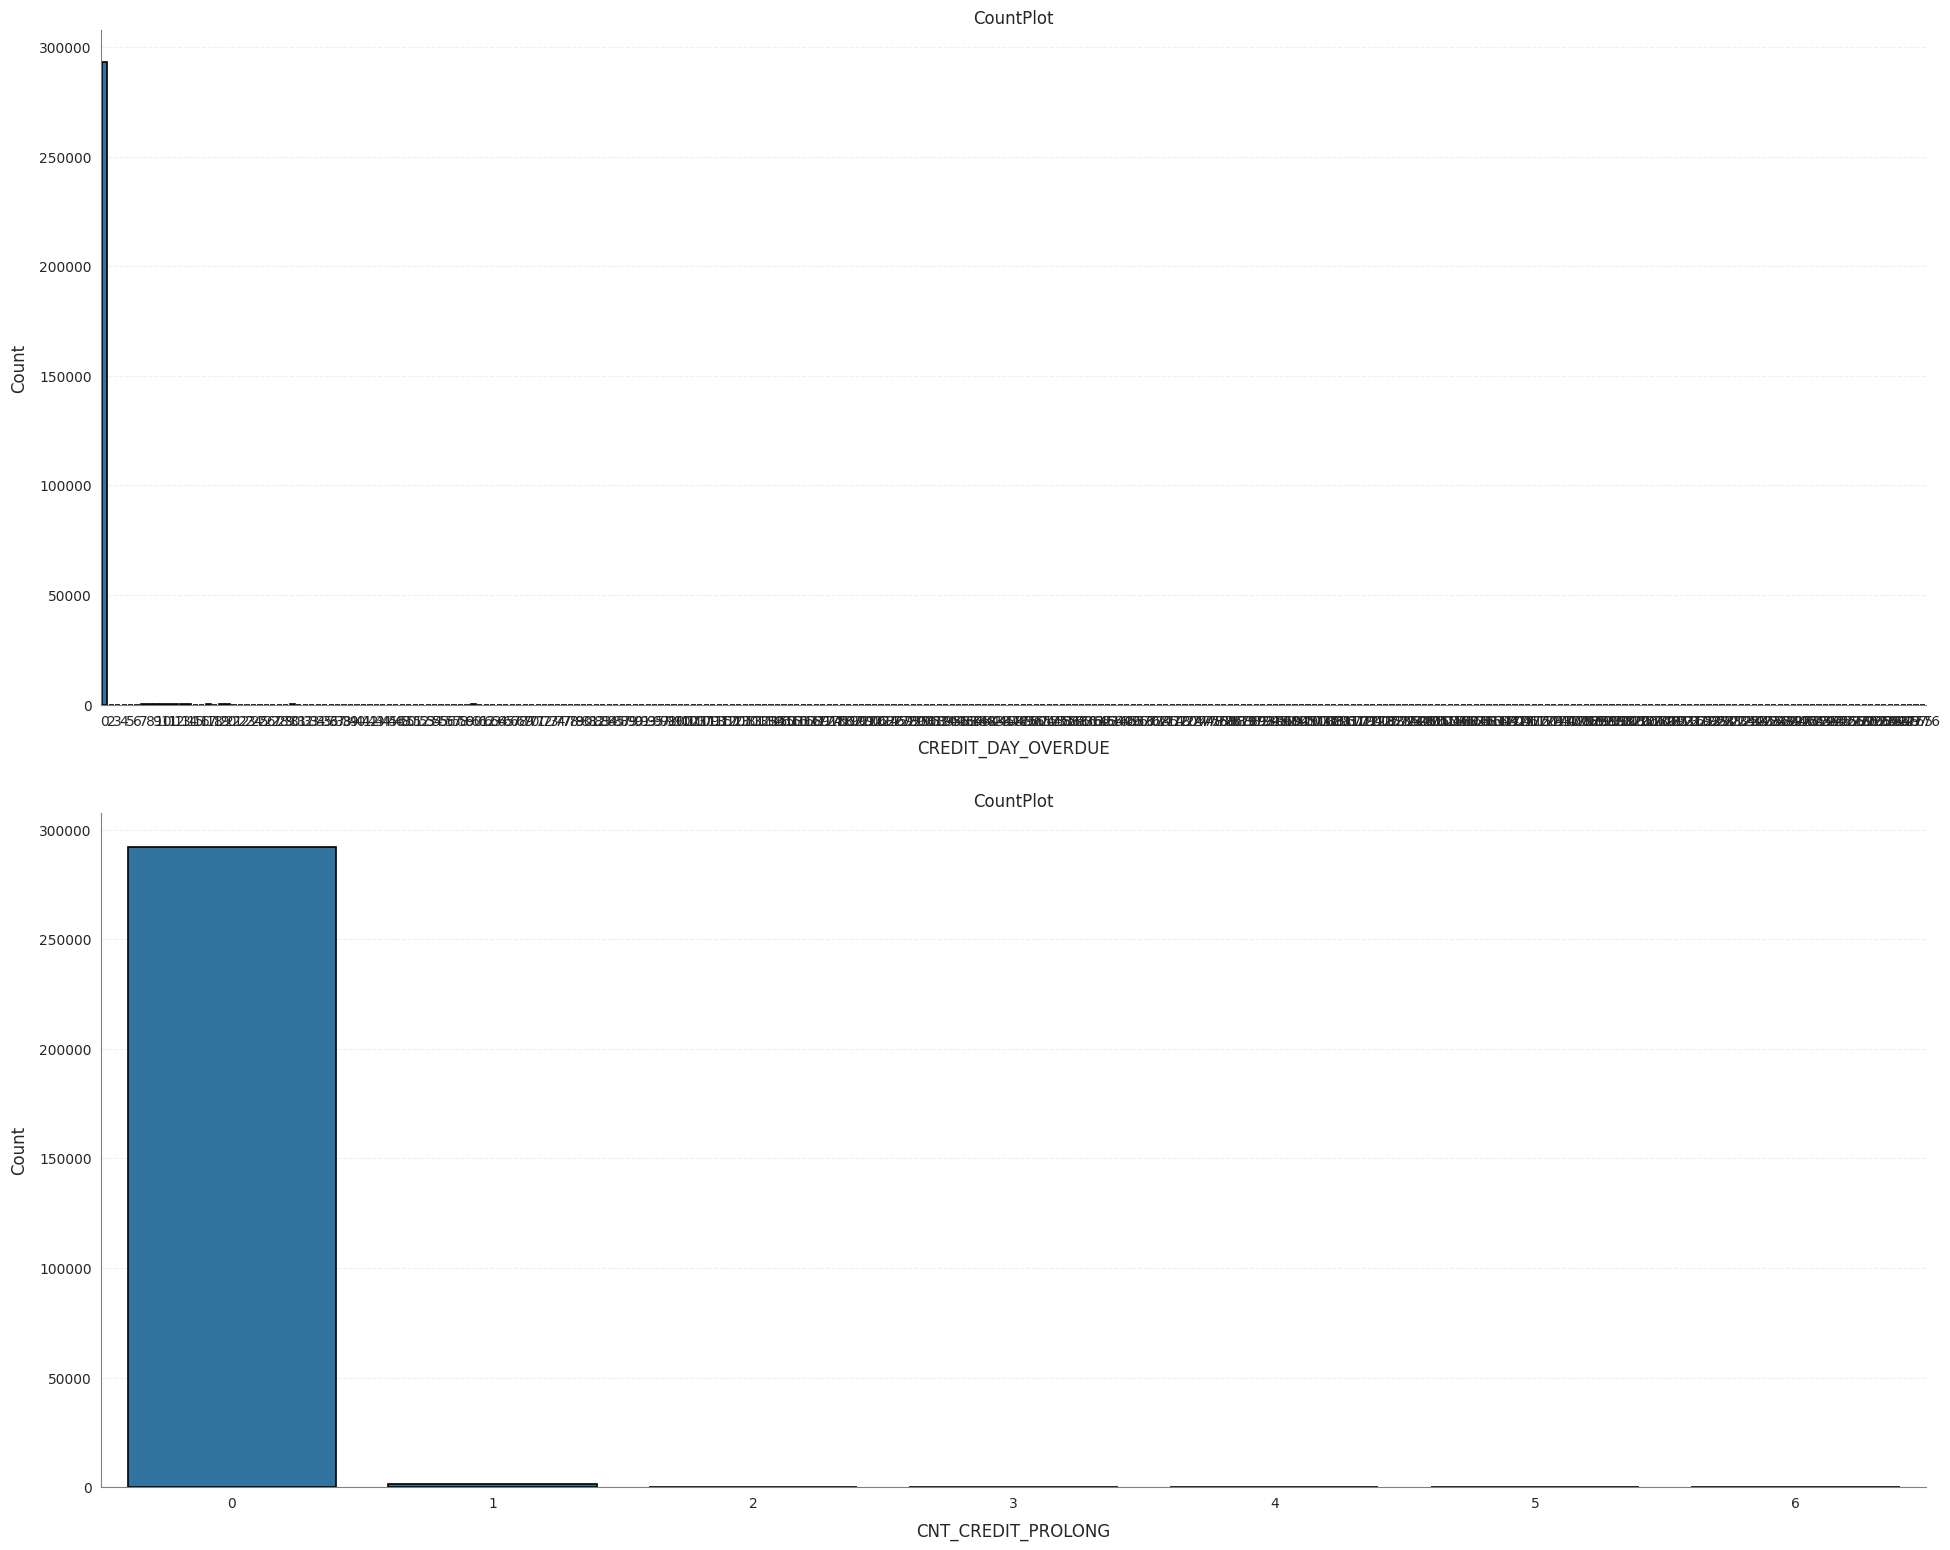

In [75]:
# phân phối của dtype int
all_columns = list(bureau_int.columns)

countplotter = CountPlot(bureau_int)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

Cả 2 cột này số lượng dữ liệu bị lệch là quá lớn và phân phối của 2 cột đều giống nhau nên sẽ bỏ cả 2 cột này

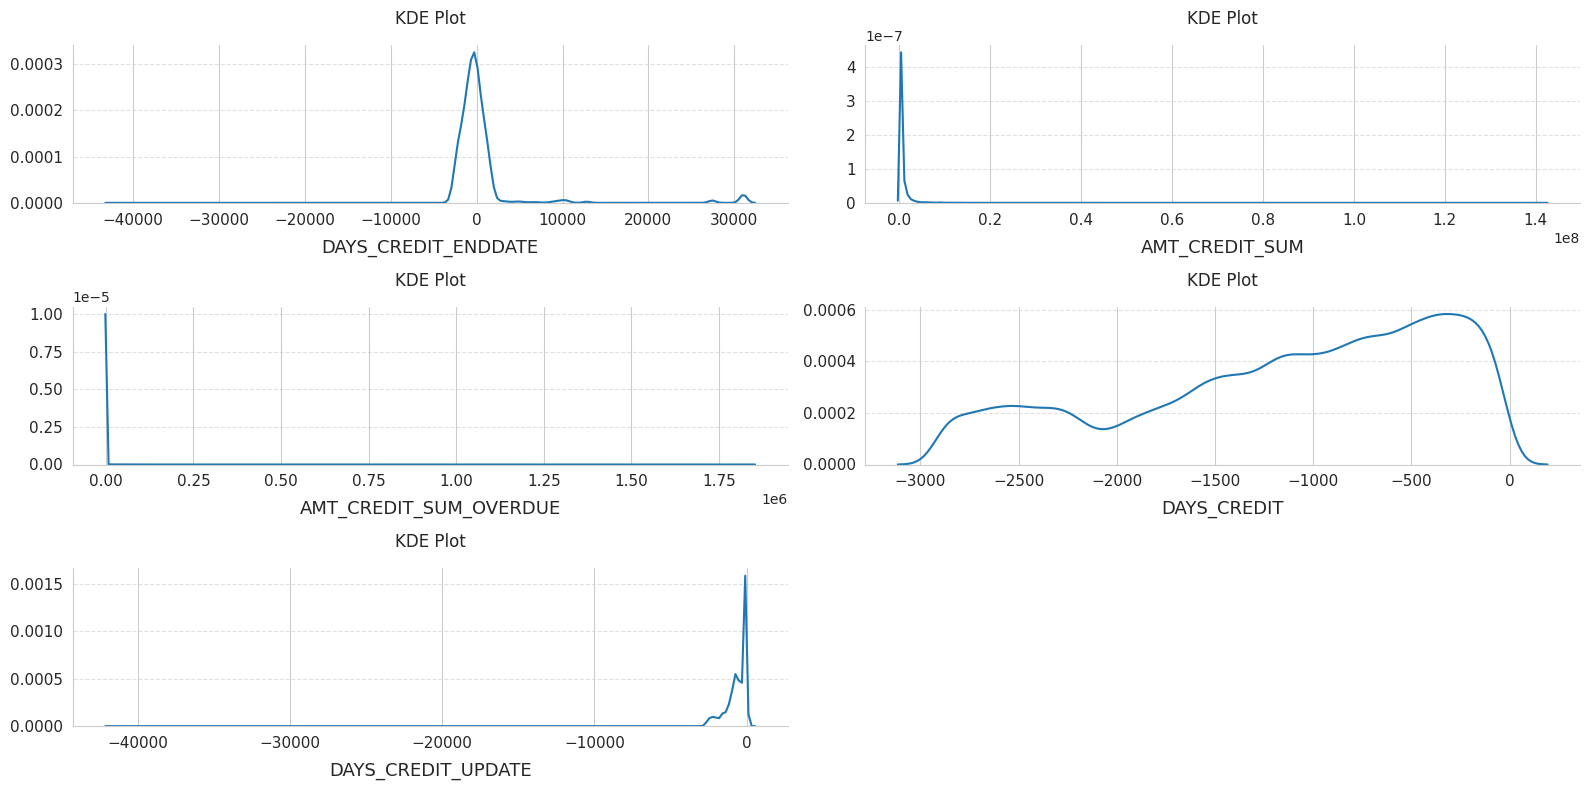

In [77]:
# phân phối của dtype float
all_columns = list(bureau_float.columns)

kdeplotter = KDEPlot(bureau_float)
kde_arg = {
    'x_axis_list': all_columns,
    'y_axis_list': [None for _ in range(len(all_columns))],
    'hue_list': [None for _ in range(len(all_columns))],
    'readable_label': False,
    'plots_each_row': 2,
    'kwarg': dict(fill=False, alpha=1)
}

fig, axes = kdeplotter.multiple_plots(**kde_arg)

một số cột bị lệch và chứa nhiều outliers, cần xử lý

## Cho bureau_balance

In [8]:
bureau_balance_int = bureau_balance_filtered.select_dtypes(include=['int64'])
bureau_balance_int.drop(columns=['SK_ID_BUREAU'], inplace=True)

bureau_balance_object = bureau_balance_filtered.select_dtypes(include=['object'])

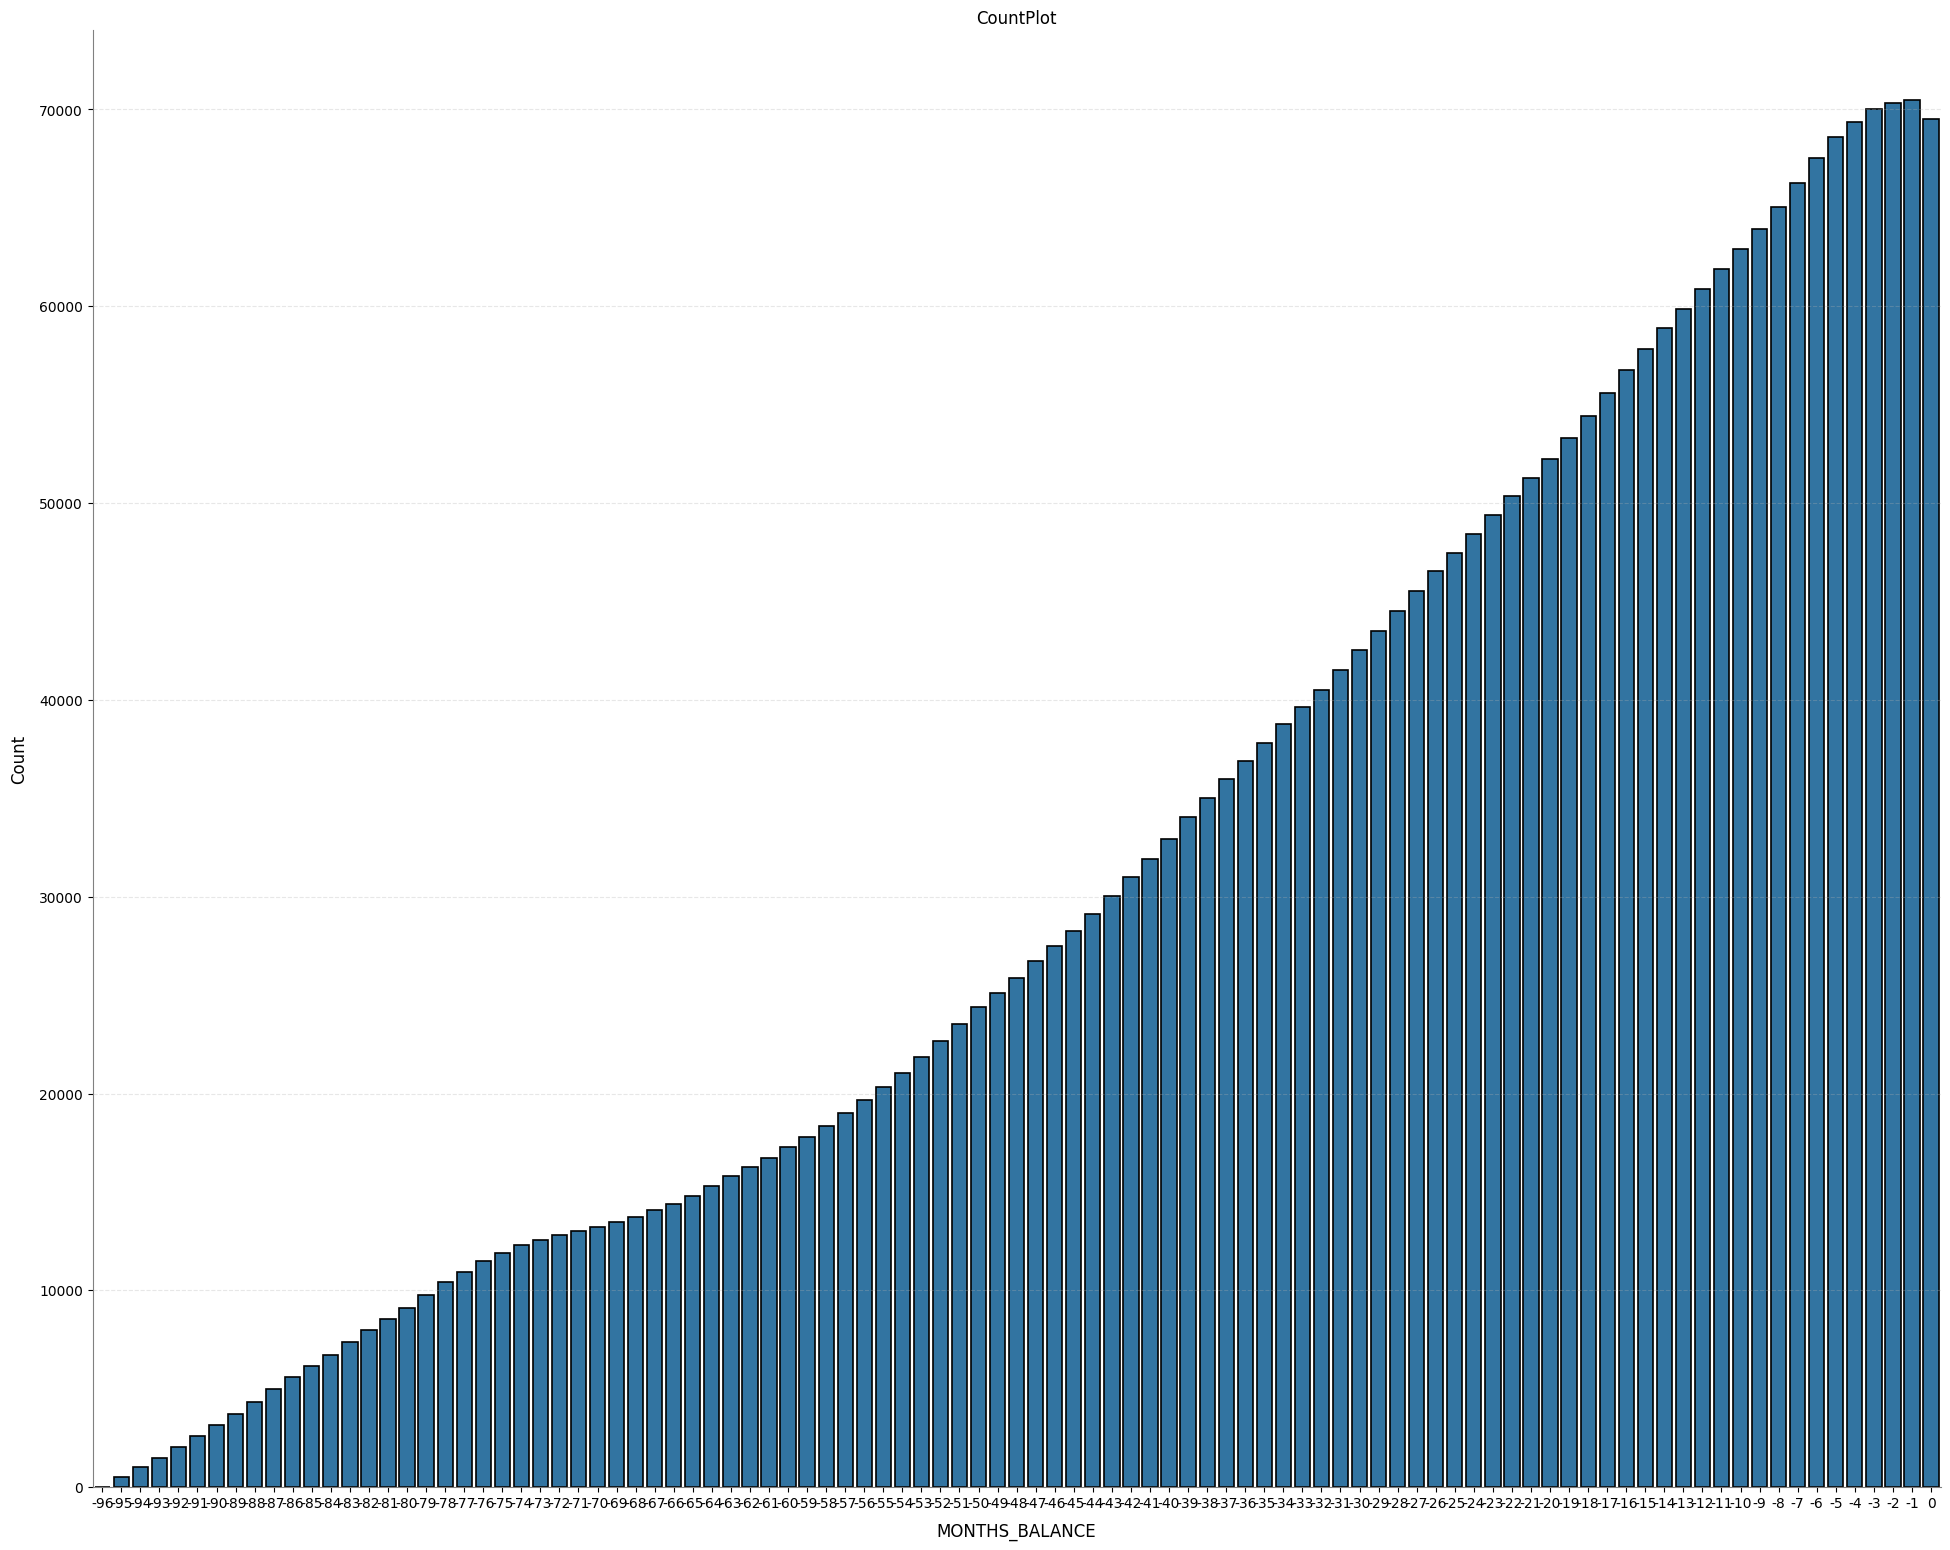

In [9]:
# phân phối của dtype int
all_columns = list(bureau_balance_int.columns)

countplotter = CountPlot(bureau_balance_int)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

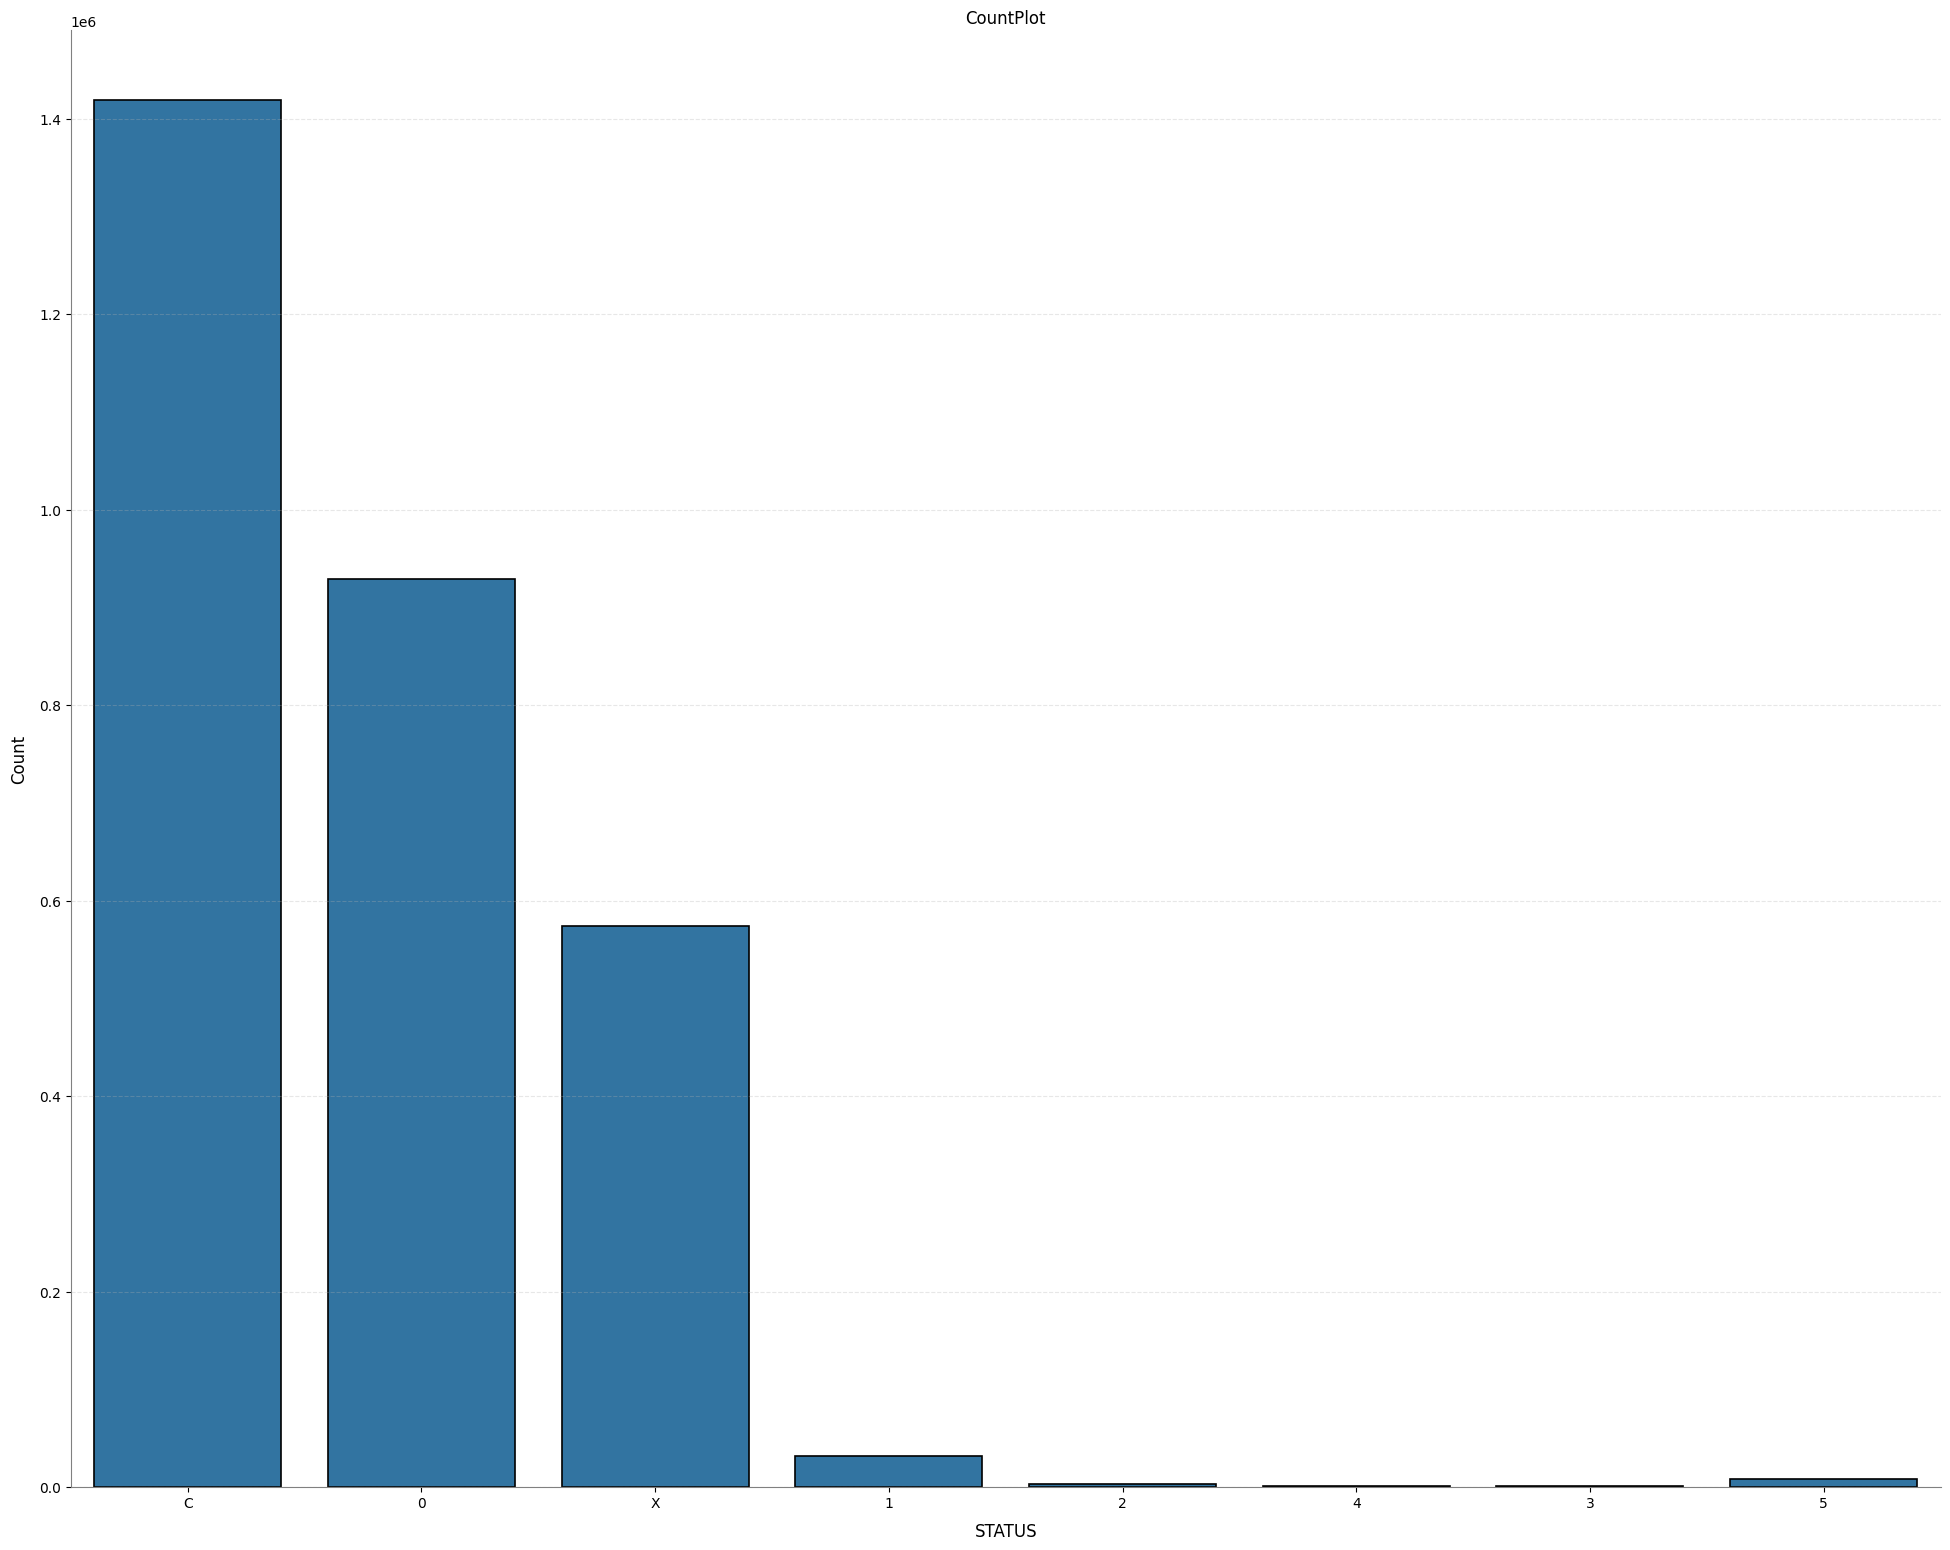

In [10]:
# phân phối của dtype object
all_columns = list(bureau_balance_object.columns)

countplotter = CountPlot(bureau_balance_object)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

## Cho credit_card_balance

In [11]:
credit_card_balance_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 475056 entries, 0 to 475055
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   SK_ID_PREV                 475056 non-null  int64  
 1   SK_ID_CURR                 475056 non-null  int64  
 2   MONTHS_BALANCE             475056 non-null  int64  
 3   AMT_BALANCE                475056 non-null  float64
 4   AMT_CREDIT_LIMIT_ACTUAL    475056 non-null  int64  
 5   AMT_DRAWINGS_CURRENT       475056 non-null  float64
 6   AMT_INST_MIN_REGULARITY    435881 non-null  float64
 7   AMT_PAYMENT_TOTAL_CURRENT  475056 non-null  float64
 8   AMT_RECEIVABLE_PRINCIPAL   475056 non-null  float64
 9   AMT_RECIVABLE              475056 non-null  float64
 10  AMT_TOTAL_RECEIVABLE       475056 non-null  float64
 11  CNT_DRAWINGS_CURRENT       475056 non-null  int64  
 12  CNT_INSTALMENT_MATURE_CUM  435881 non-null  float64
 13  NAME_CONTRACT_STATUS       47

In [12]:
credit_card_balance_filtered.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1864742,303581,-1,0.000,45000,0.0,0.000,0.0,0.00,0.000,0.000,0,59.0,Active,0,0
1,2037377,289902,-1,131294.340,135000,0.0,6774.660,6975.0,128518.02,131294.340,131294.340,0,11.0,Active,0,0
2,2016842,302450,-3,0.000,0,0.0,0.000,0.0,0.00,0.000,0.000,0,2.0,Completed,0,0
3,1288249,406607,-4,0.000,270000,0.0,0.000,0.0,0.00,0.000,0.000,0,80.0,Active,0,0
4,2043751,441030,-4,436537.755,450000,4500.0,23238.585,23400.0,421431.93,435192.255,435192.255,1,26.0,Active,0,0


In [14]:
credit_card_balance_object = credit_card_balance_filtered.select_dtypes(include=['object'])
credit_card_balance_int = credit_card_balance_filtered.select_dtypes(include=['int64'])
credit_card_balance_float = credit_card_balance_filtered.select_dtypes(include=['float64'])

credit_card_balance_int.drop(columns=['SK_ID_PREV', 'SK_ID_CURR'], inplace=True)

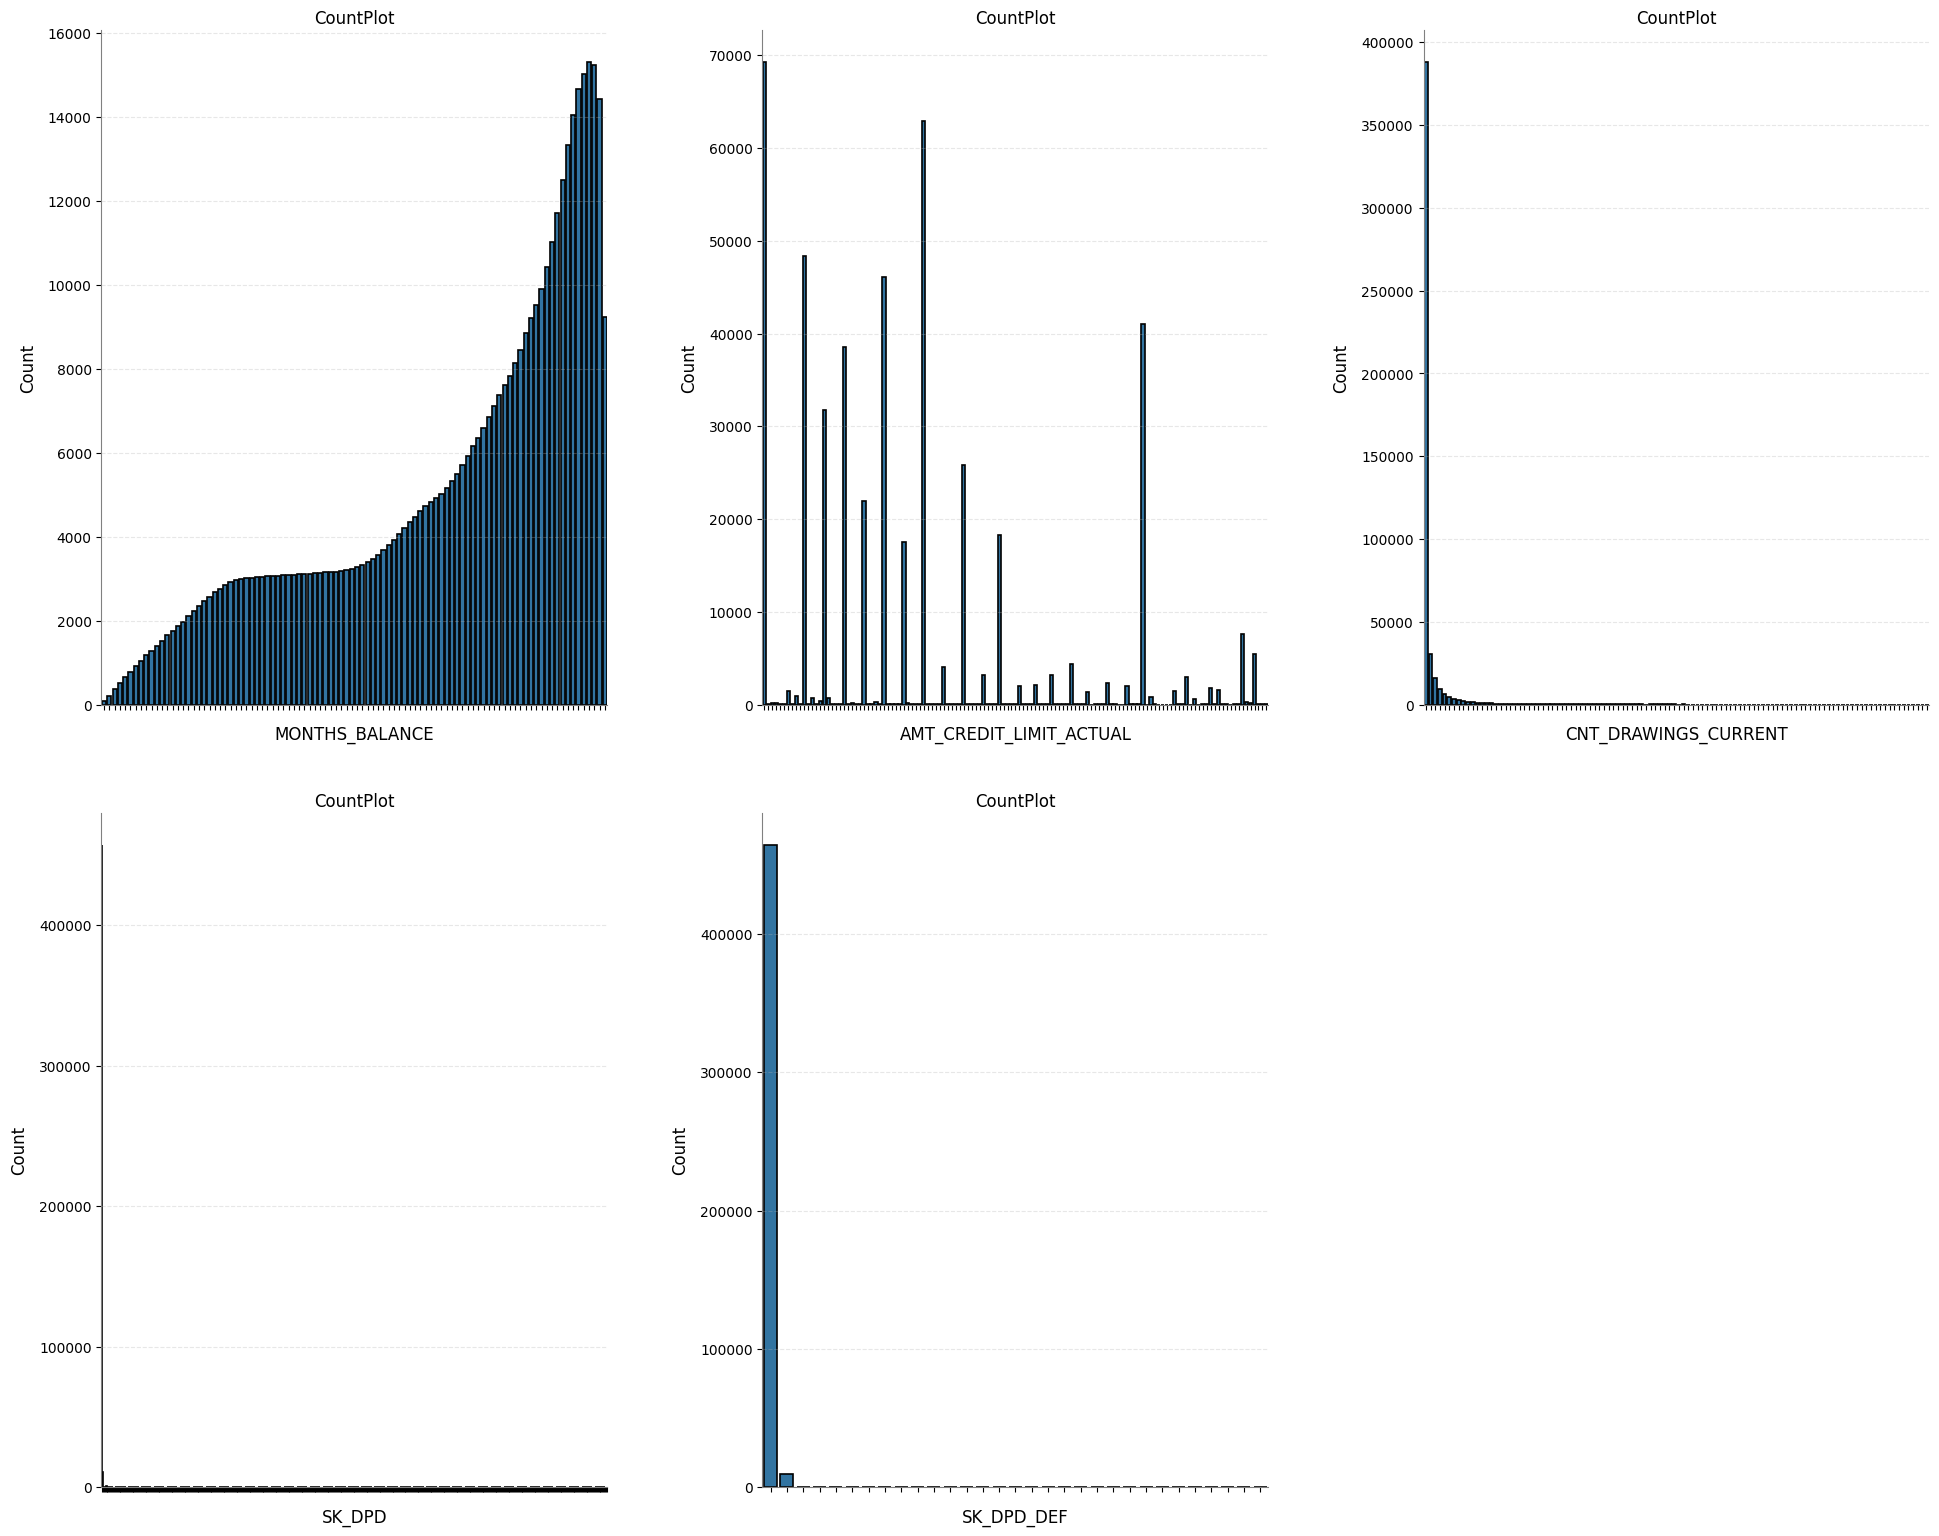

In [26]:
# phân phối của dtype int
all_columns = list(credit_card_balance_int.columns)

countplotter = CountPlot(credit_card_balance_int)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=3, readable_label=False)

for ax in axes.flatten():
    ax.set_xticklabels([])

SK_DPD và SK_DPD_DEF có sự trùng lặp thông tin nên có thể bỏ 1 trong 2 cột, hoặc bỏ hết cả 2 vì 2 cột này lệch quá nhiều

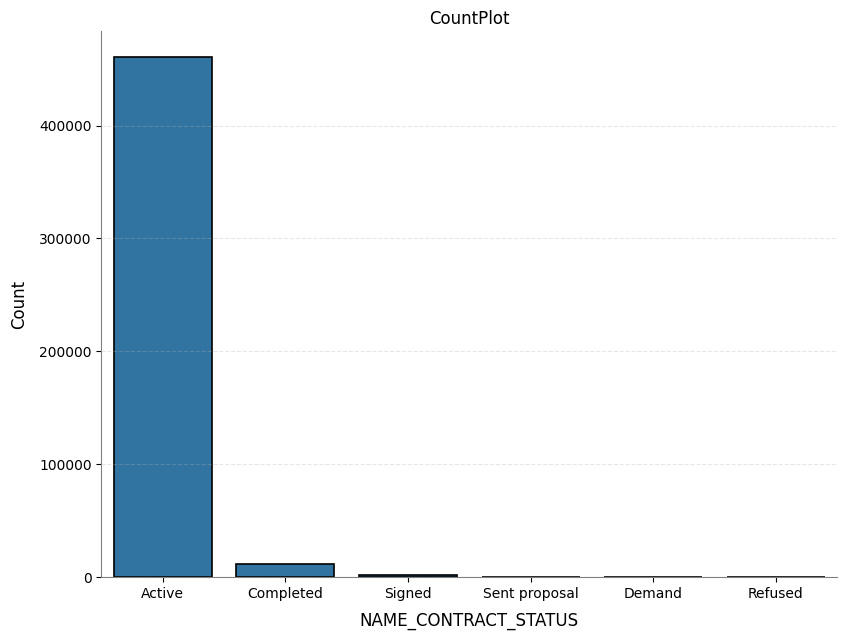

In [17]:
# phân phối của dtype object
all_columns = list(credit_card_balance_object.columns)

countplotter = CountPlot(credit_card_balance_object)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

fig.set_size_inches(8, 6)

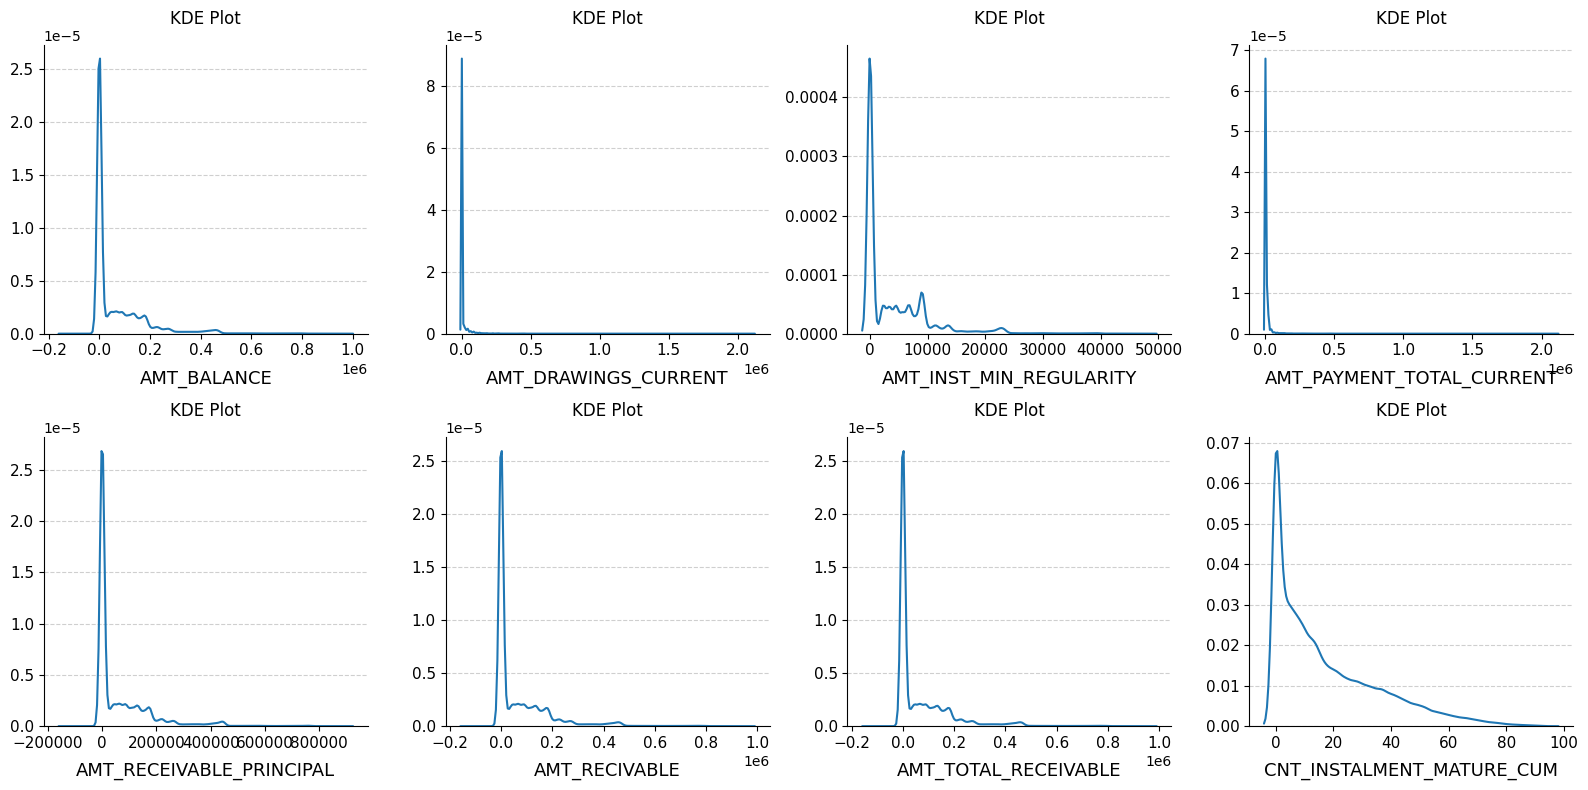

In [28]:
# phân phối của dtype float
all_columns = list(credit_card_balance_float.columns)

kdeplotter = KDEPlot(credit_card_balance_float)
kde_arg = {
    'x_axis_list': all_columns,
    'y_axis_list': [None for _ in range(len(all_columns))],
    'hue_list': [None for _ in range(len(all_columns))],
    'readable_label': False,
    'plots_each_row': 4,
    'kwarg': dict(fill=False, alpha=1)
}

fig, axes = kdeplotter.multiple_plots(**kde_arg)

## Cho installments_payments

In [34]:
installments_payments_int_float = installments_payments_filtered.select_dtypes(include=['int64', 'float64'])

installments_payments_int_float.drop(columns=['SK_ID_PREV', 'SK_ID_CURR'], inplace=True)

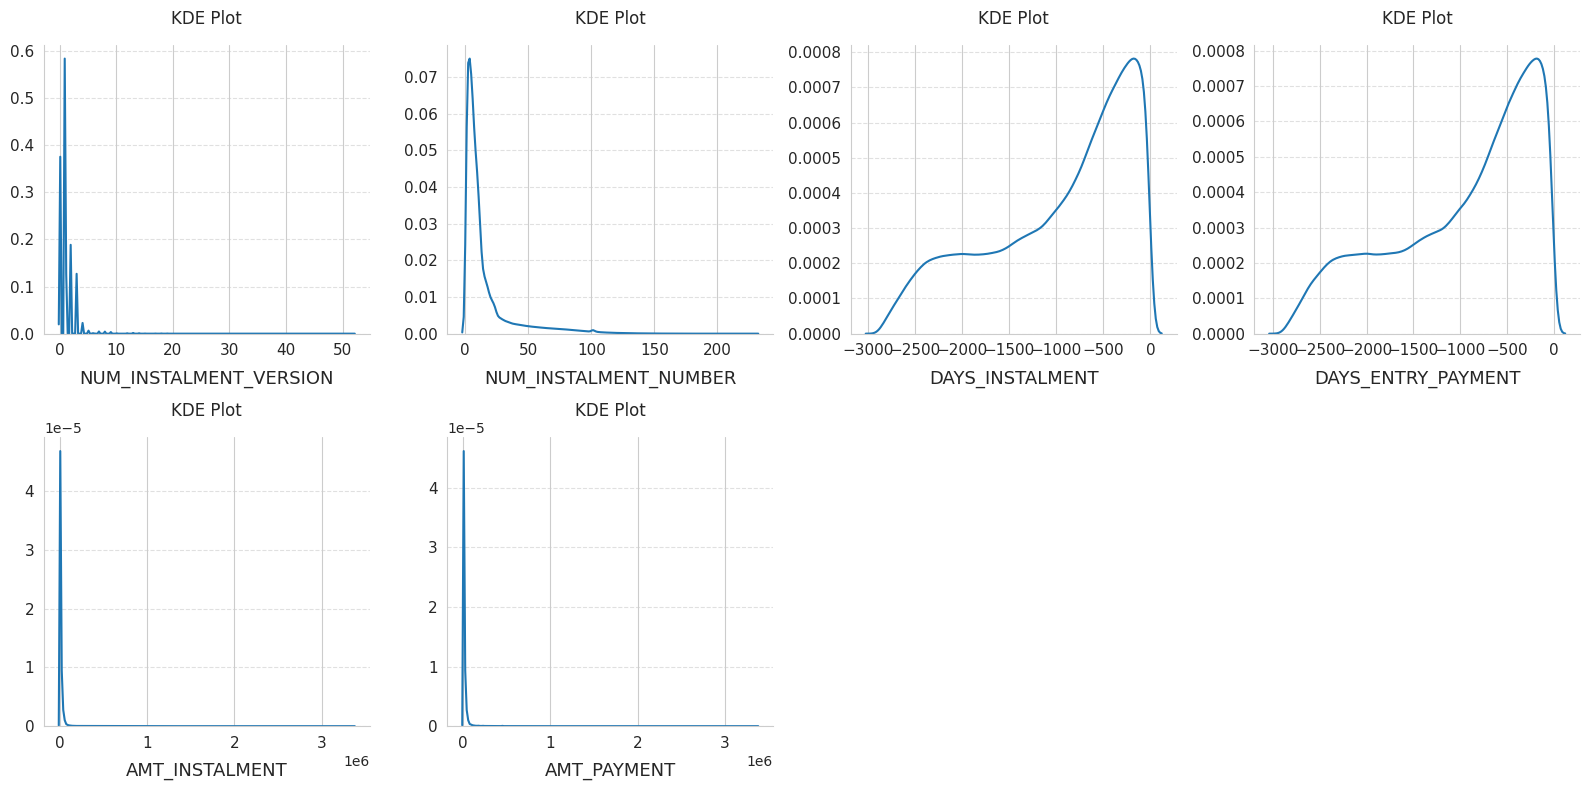

In [35]:
all_columns = list(installments_payments_int_float.columns)

kdeplotter = KDEPlot(installments_payments_int_float)
kde_arg = {
    'x_axis_list': all_columns,
    'y_axis_list': [None for _ in range(len(all_columns))],
    'hue_list': [None for _ in range(len(all_columns))],
    'readable_label': False,
    'plots_each_row': 4,
    'kwarg': dict(fill=False, alpha=1)
}

fig, axes = kdeplotter.multiple_plots(**kde_arg)

## Cho previous_application

In [42]:
previous_application_object = previous_application_filtered.select_dtypes(include=['object'])
previous_application_int = previous_application_filtered.select_dtypes(include=['int64'])
previous_application_float = previous_application_filtered.select_dtypes(include=['float64'])

previous_application_int.drop(columns=['SK_ID_CURR', 'SK_ID_PREV', 'DAYS_DECISION', 'SELLERPLACE_AREA'], inplace=True)
previous_application_float = pd.concat([previous_application_float, previous_application_filtered[['DAYS_DECISION', 'SELLERPLACE_AREA']]], axis=1)

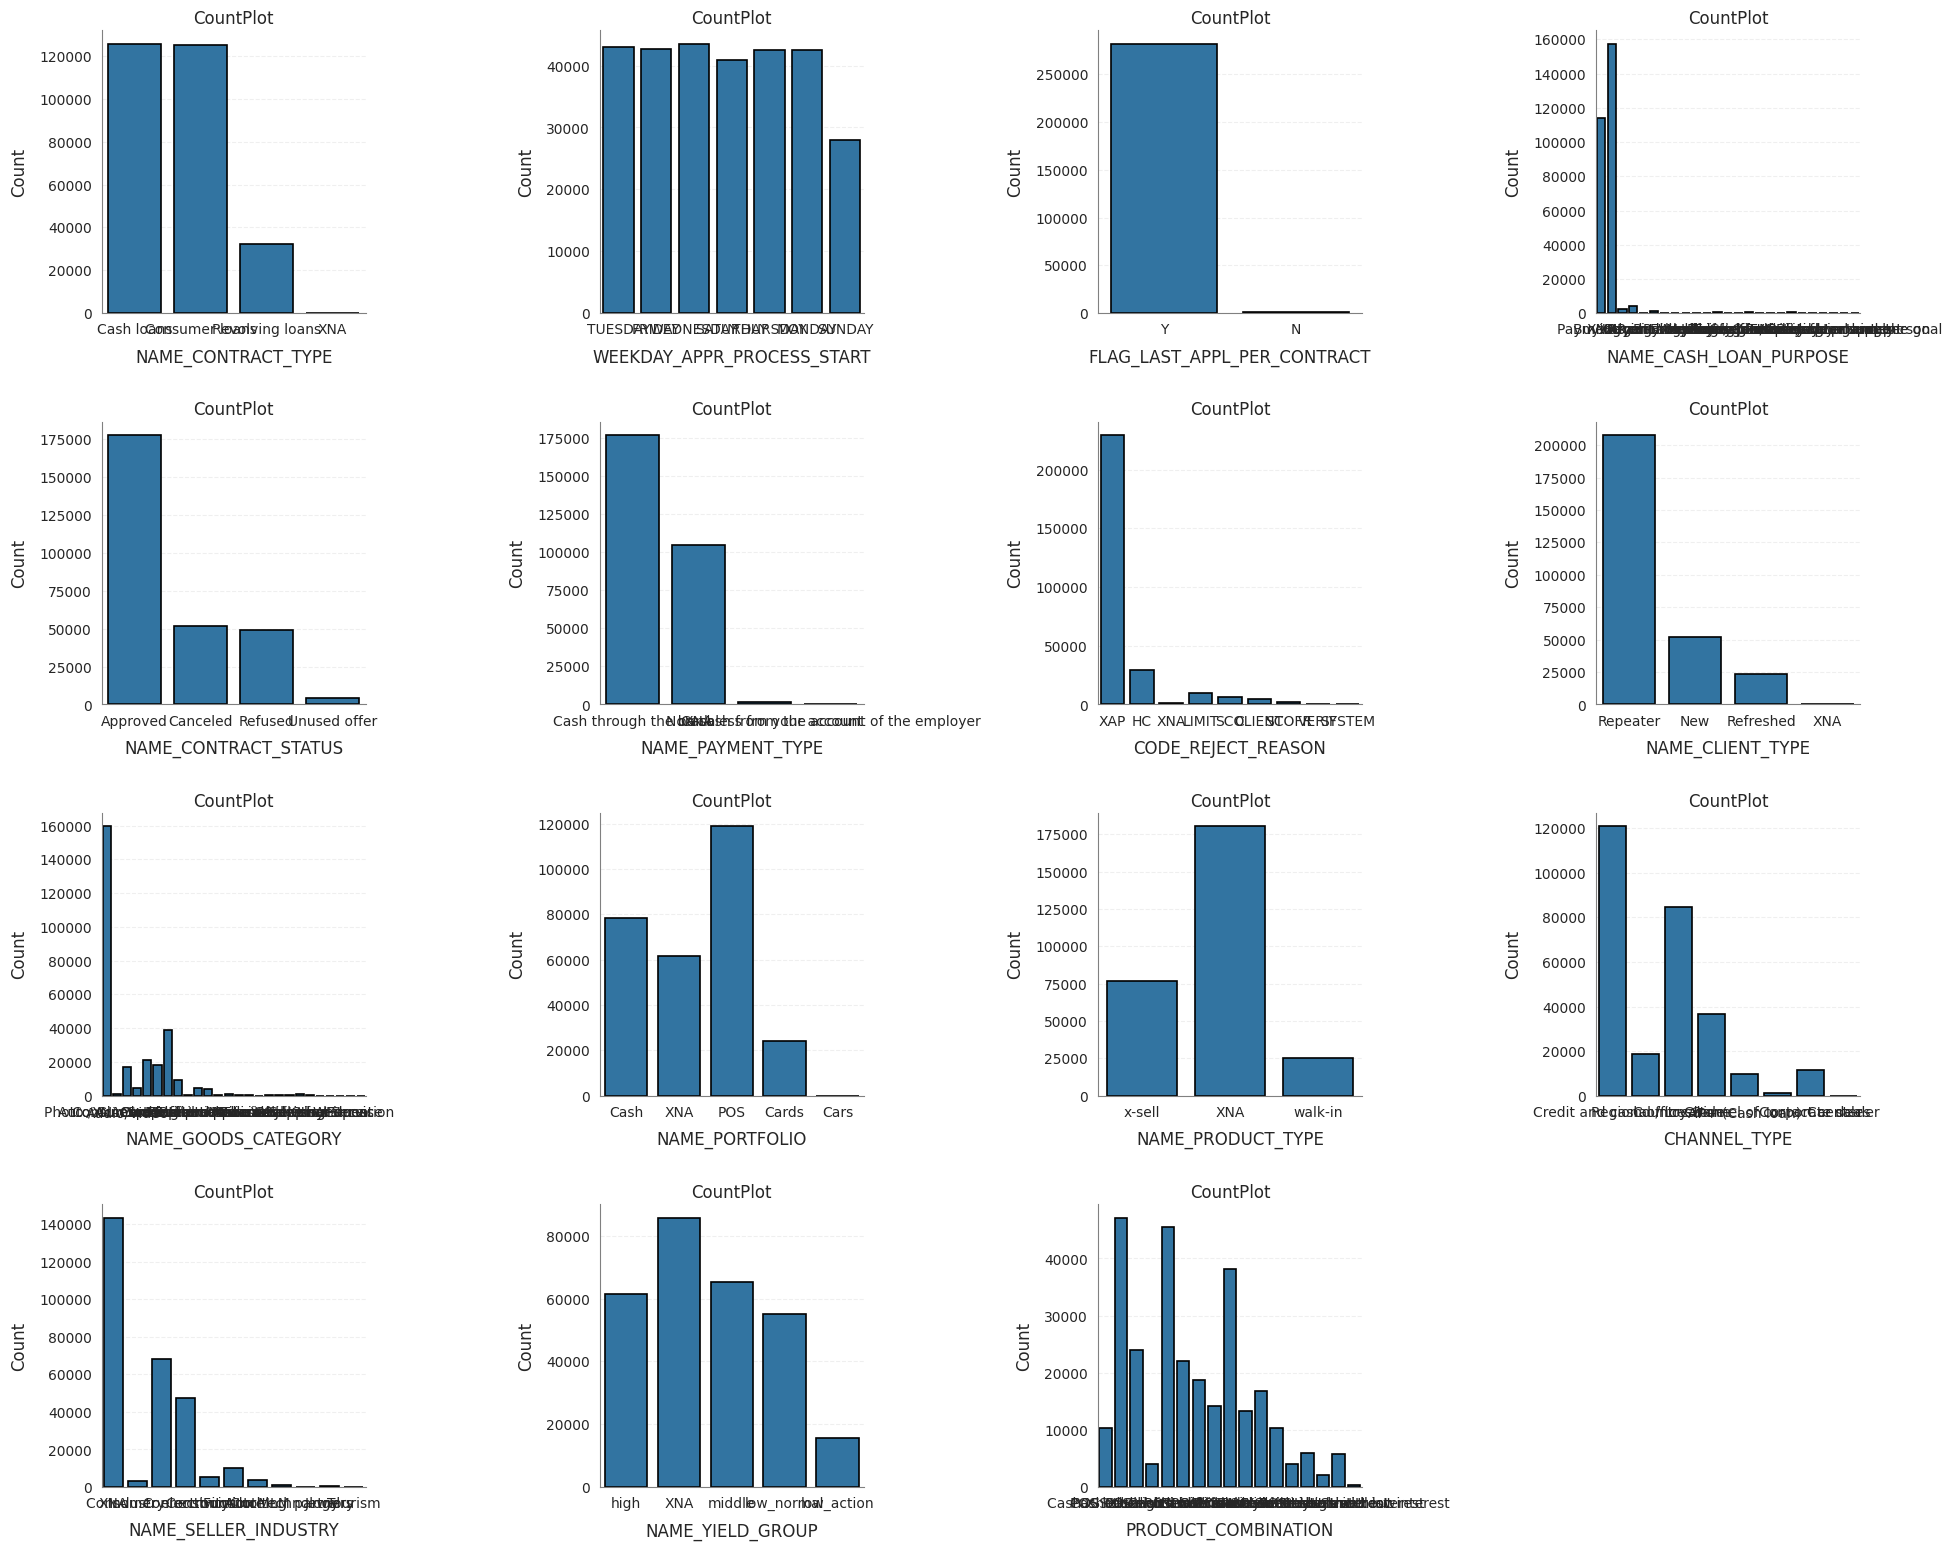

In [40]:
# phân phối của dtype object
all_columns = list(previous_application_object.columns)

countplotter = CountPlot(previous_application_object)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=4, readable_label=False)

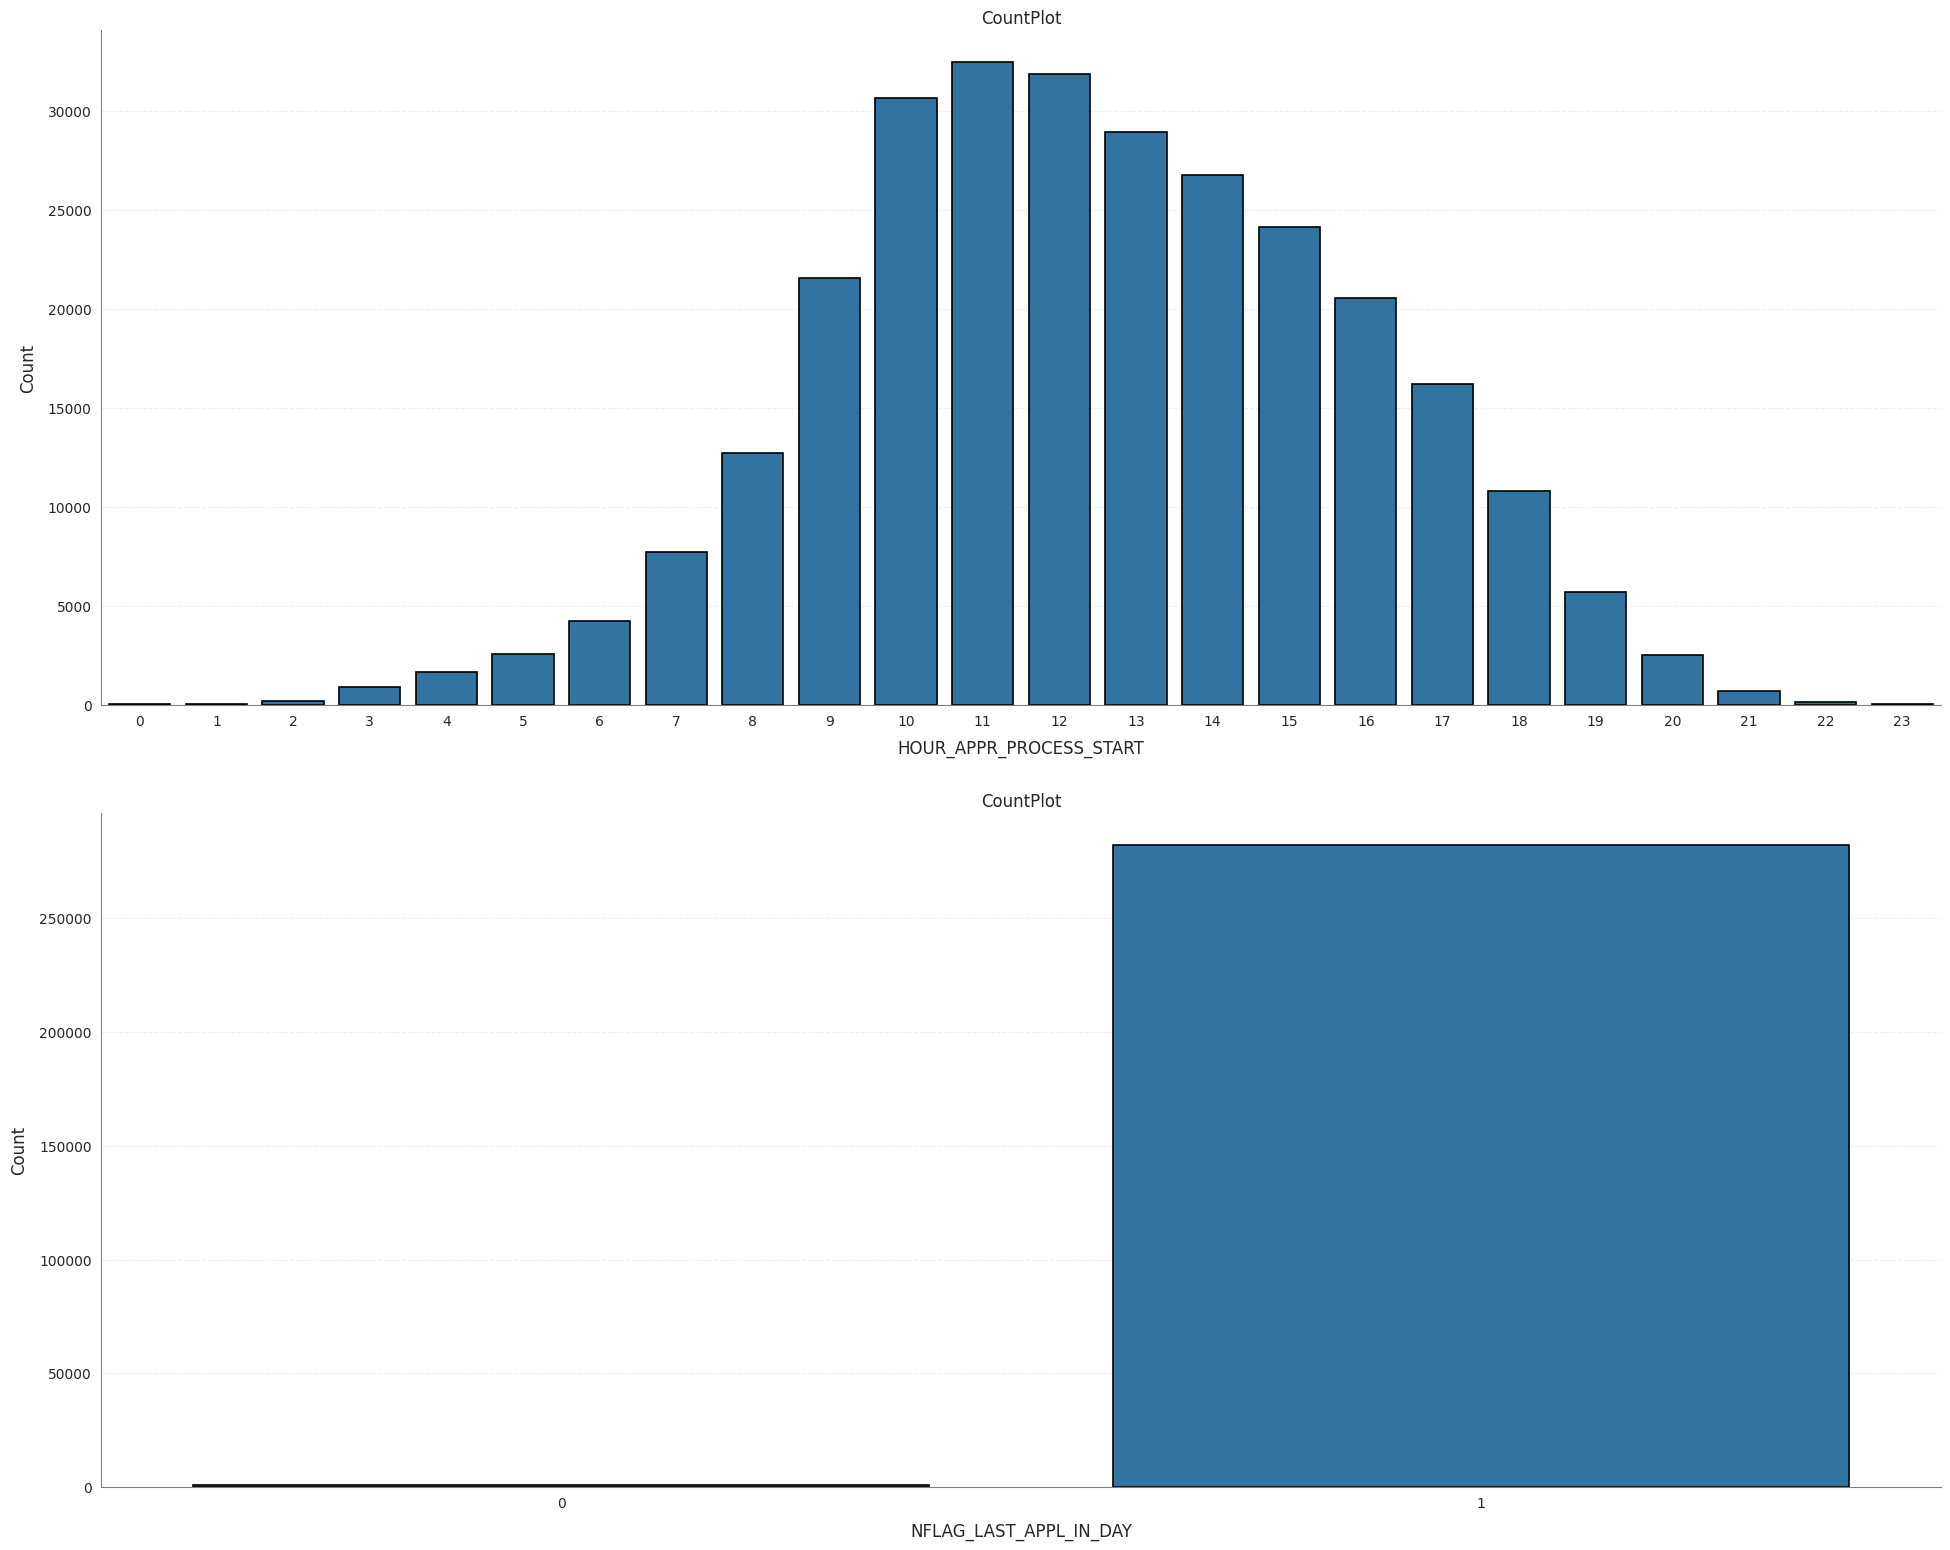

In [43]:
# phân phối của dtype int
all_columns = list(previous_application_int.columns)

countplotter = CountPlot(previous_application_int)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

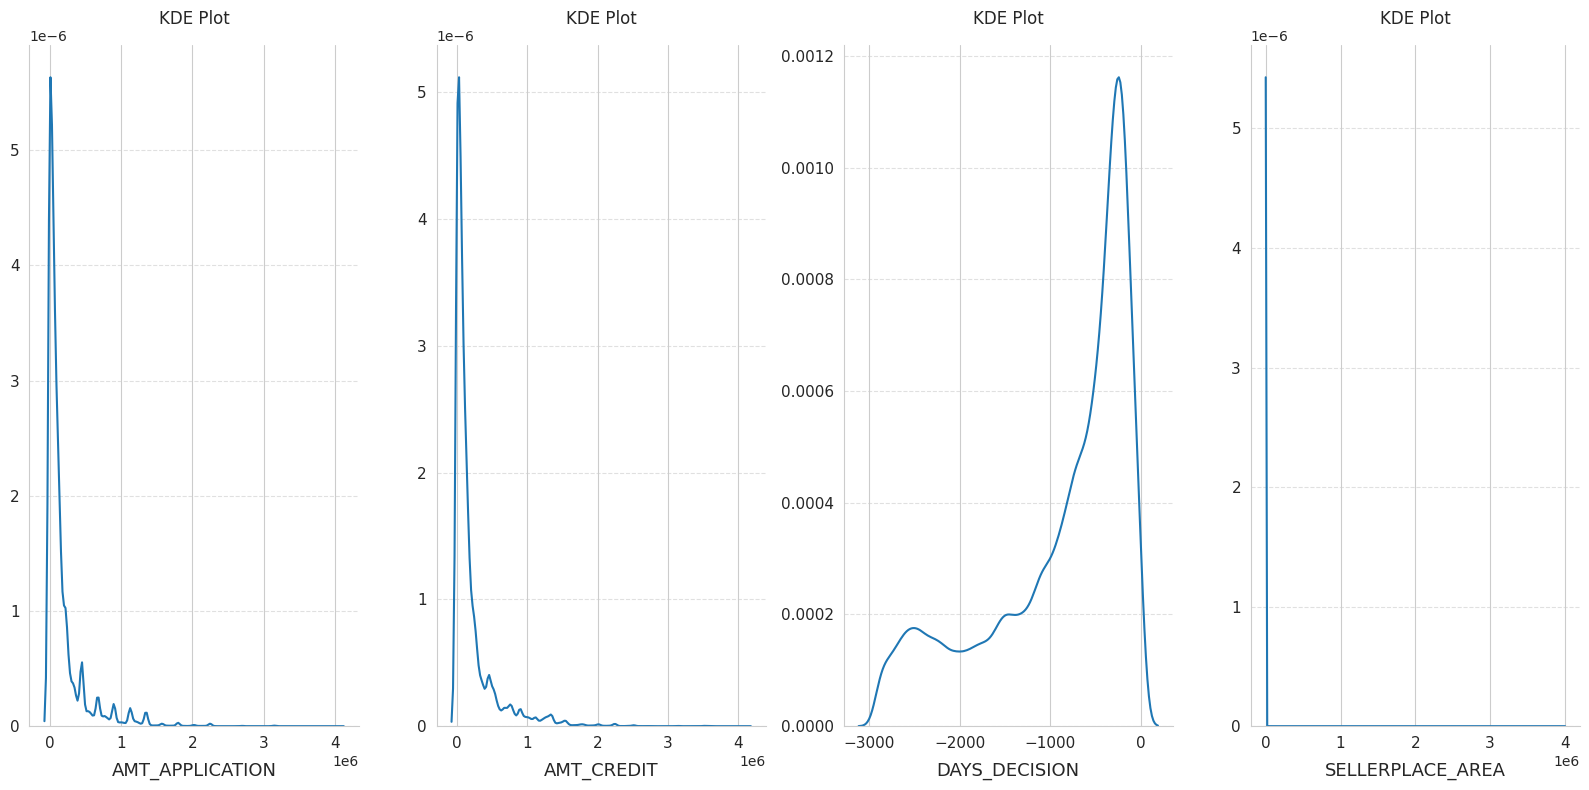

In [44]:
# phân phối của dtype float
all_columns = list(previous_application_float.columns)

kdeplotter = KDEPlot(previous_application_float)
kde_arg = {
    'x_axis_list': all_columns,
    'y_axis_list': [None for _ in range(len(all_columns))],
    'hue_list': [None for _ in range(len(all_columns))],
    'readable_label': False,
    'plots_each_row': 4,
    'kwarg': dict(fill=False, alpha=1)
}

fig, axes = kdeplotter.multiple_plots(**kde_arg)

## Cho POS_CASH_balance

In [49]:
POS_CASH_balance_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1650244 entries, 0 to 1650243
Data columns (total 8 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   SK_ID_PREV             1650244 non-null  int64  
 1   SK_ID_CURR             1650244 non-null  int64  
 2   MONTHS_BALANCE         1650244 non-null  int64  
 3   CNT_INSTALMENT         1645888 non-null  float64
 4   CNT_INSTALMENT_FUTURE  1645884 non-null  float64
 5   NAME_CONTRACT_STATUS   1650244 non-null  object 
 6   SK_DPD                 1650244 non-null  int64  
 7   SK_DPD_DEF             1650244 non-null  int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 100.7+ MB


In [50]:
POS_CASH_balance_object = POS_CASH_balance_filtered.select_dtypes(include=['object'])
POS_CASH_balance_int = POS_CASH_balance_filtered.select_dtypes(include=['int64'])
POS_CASH_balance_float = POS_CASH_balance_filtered.select_dtypes(include=['float64'])

POS_CASH_balance_int.drop(columns=['SK_ID_CURR', 'SK_ID_PREV'], inplace=True)

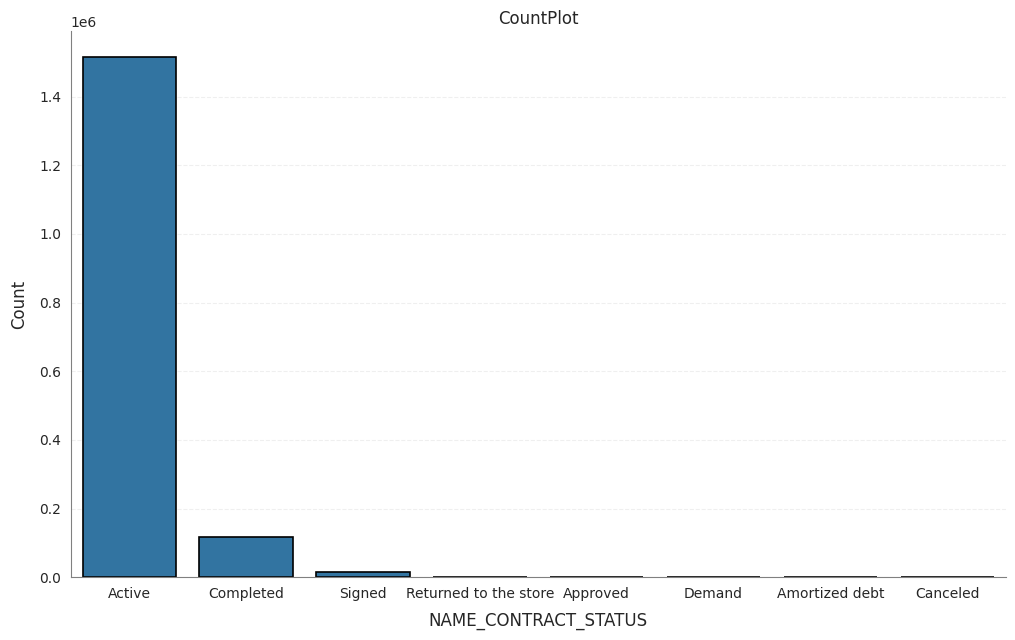

In [54]:
# phân phối của dtype object
all_columns = list(POS_CASH_balance_object.columns)

countplotter = CountPlot(POS_CASH_balance_object)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=1, readable_label=False)

fig.set_size_inches(10, 6)

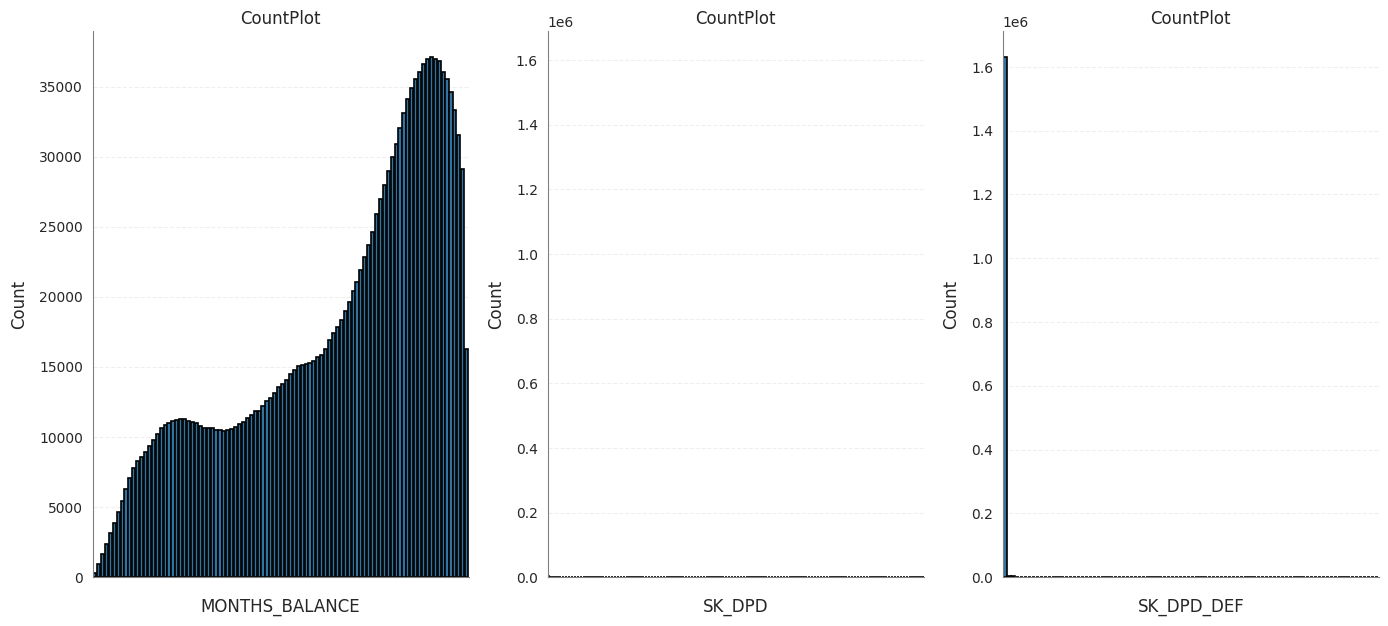

In [61]:
# phân phối của dtype int
all_columns = list(POS_CASH_balance_int.columns)

countplotter = CountPlot(POS_CASH_balance_int)

x_axis_list = all_columns
hue_list = [None for _ in range(len(all_columns))]

fig, axes = countplotter.multiple_plots(x_axis_list=x_axis_list, hue_list=hue_list, kwarg=None,
                       plots_each_row=3, readable_label=False)

fig.set_size_inches(14, 6)

for ax in axes.flatten():
    ax.set_xticklabels([])

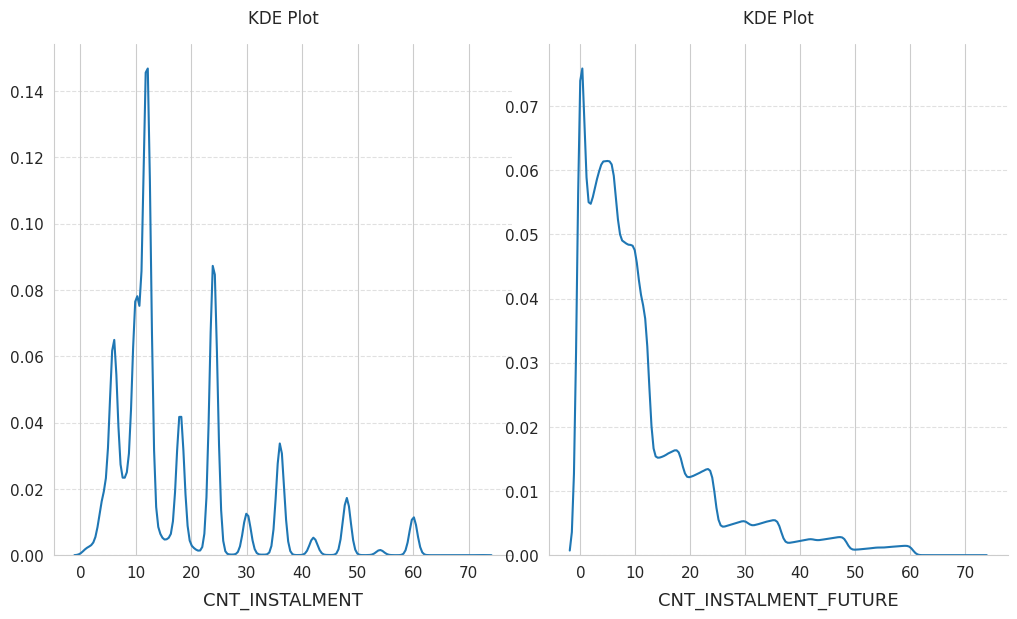

In [63]:
# phân phối của dtype float
all_columns = list(POS_CASH_balance_float.columns)

kdeplotter = KDEPlot(POS_CASH_balance_float)
kde_arg = {
    'x_axis_list': all_columns,
    'y_axis_list': [None for _ in range(len(all_columns))],
    'hue_list': [None for _ in range(len(all_columns))],
    'readable_label': False,
    'plots_each_row': 2,
    'kwarg': dict(fill=False, alpha=1)
}

fig, axes = kdeplotter.multiple_plots(**kde_arg)

fig.set_size_inches(10, 6)

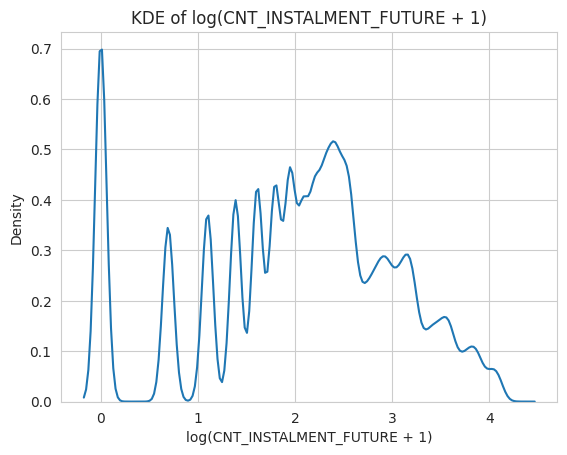

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.kdeplot(np.log(POS_CASH_balance_float['CNT_INSTALMENT_FUTURE'] + 1))
plt.title('KDE of log(CNT_INSTALMENT_FUTURE + 1)')
plt.xlabel('log(CNT_INSTALMENT_FUTURE + 1)')
plt.show()